【9章】元データ (20640, 9) → 前処理後 (18572, 8) ／ 築年数除外 1273 ／ 価格上限除外 795


,所得,築年数,地域人口,緯度,経度,部屋数/人,寝室数/人,住宅価格
0,8.3252,41.0,322.0,37.88,-122.23,2.732919,0.400621,4.526
1,8.3014,21.0,2401.0,37.86,-122.22,2.956685,0.460641,3.585
8,2.0804,42.0,1206.0,37.84,-122.26,2.118574,0.551410,2.267
15,2.1250,50.0,697.0,37.85,-122.26,1.606887,0.406026,1.400
18,1.9911,50.0,990.0,37.84,-122.26,2.261616,0.459596,1.587


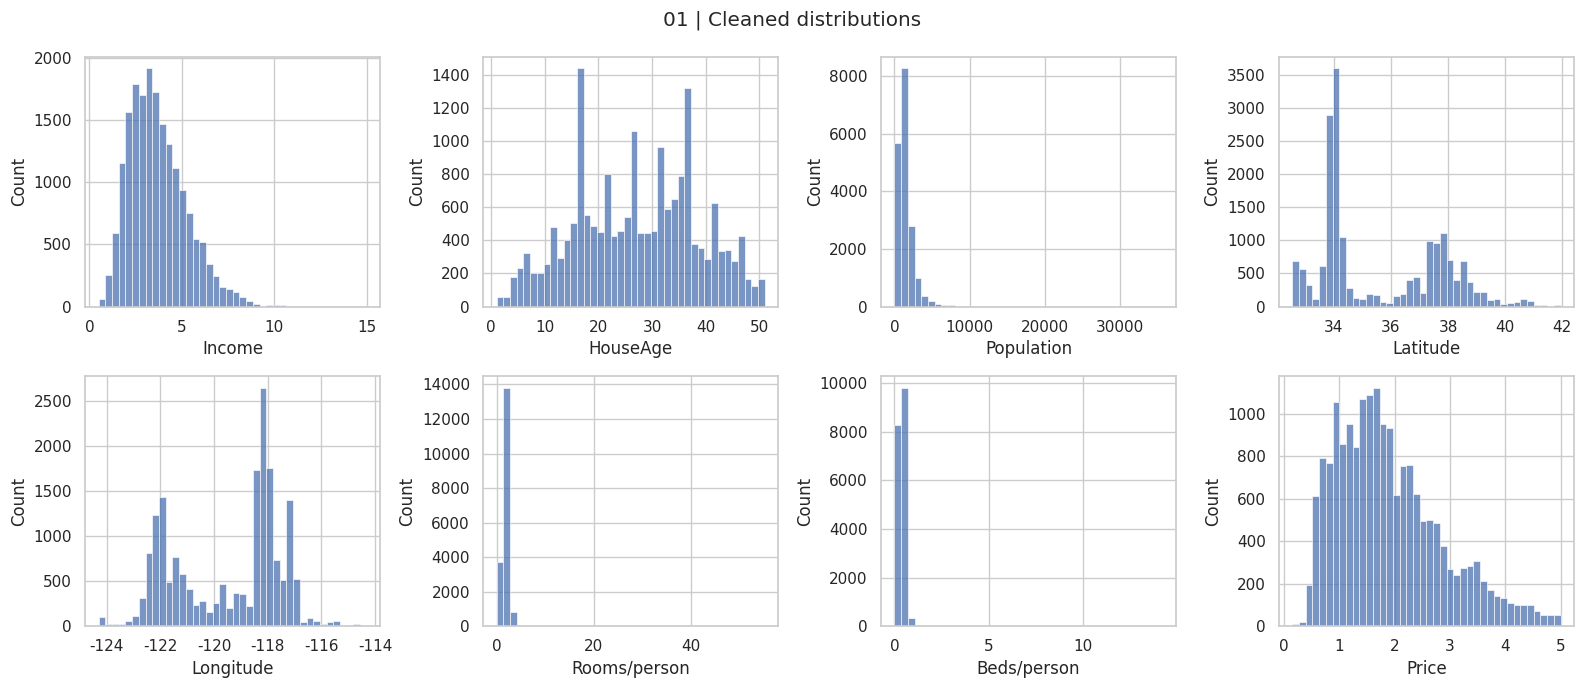

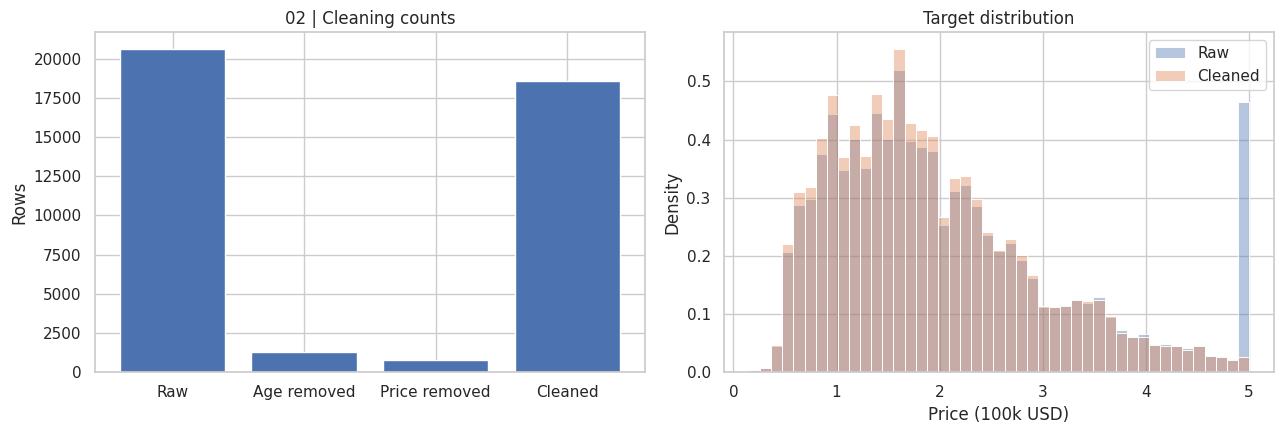

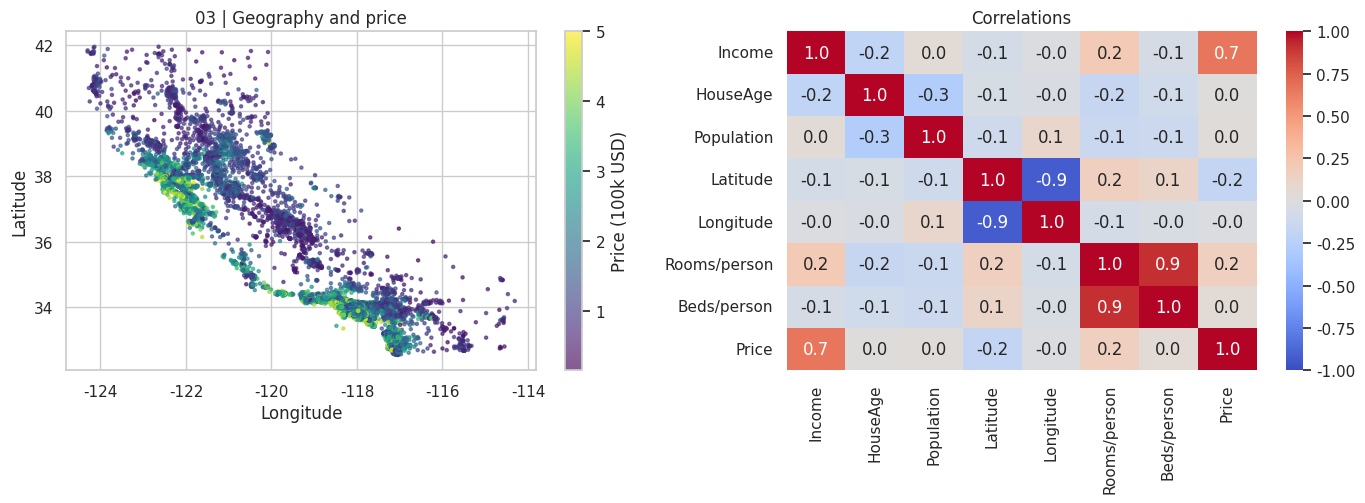

Linear                  : test R²=0.575 ／ 0.0 sec
Ridge                   : test R²=0.576 ／ 0.0 sec
Lasso                   : test R²=0.579 ／ 0.0 sec
Polynomial (degree 2)   : test R²=0.654 ／ 0.1 sec
Decision Tree           : test R²=0.693 ／ 0.1 sec ／ warnings=1
Random Forest           : test R²=0.787 ／ 4.6 sec ／ warnings=1
Gradient Boosting       : test R²=0.813 ／ 0.5 sec ／ warnings=1
SVR (RBF)               : test R²=0.754 ／ 8.8 sec ／ warnings=1
GAM (spline additive)   : test R²=0.661 ／ 0.0 sec
Neural Network (MLP)    : test R²=0.753 ／ 3.6 sec ／ warnings=1


,Model,Train R2,Test R2,MAE,RMSE,Train seconds
0,Gradient Boosting,0.8609,0.8129,0.2826,0.4161,0.4774
1,Random Forest,0.9293,0.7866,0.2957,0.4444,4.5704
2,SVR (RBF),0.7730,0.7544,0.3256,0.4767,8.7525
3,Neural Network (MLP),0.7658,0.7529,0.3356,0.4782,3.5959
4,Decision Tree,0.7877,0.6927,0.3660,0.5332,0.1055
5,GAM (spline additive),0.6490,0.6612,0.4112,0.5600,0.0303
6,Polynomial (degree 2),0.6673,0.6540,0.3990,0.5659,0.1129
7,Lasso,0.5962,0.5785,0.4498,0.6245,0.0140
8,Ridge,0.5968,0.5756,0.4493,0.6267,0.0047
9,Linear,0.5968,0.5752,0.4494,0.6270,0.0061


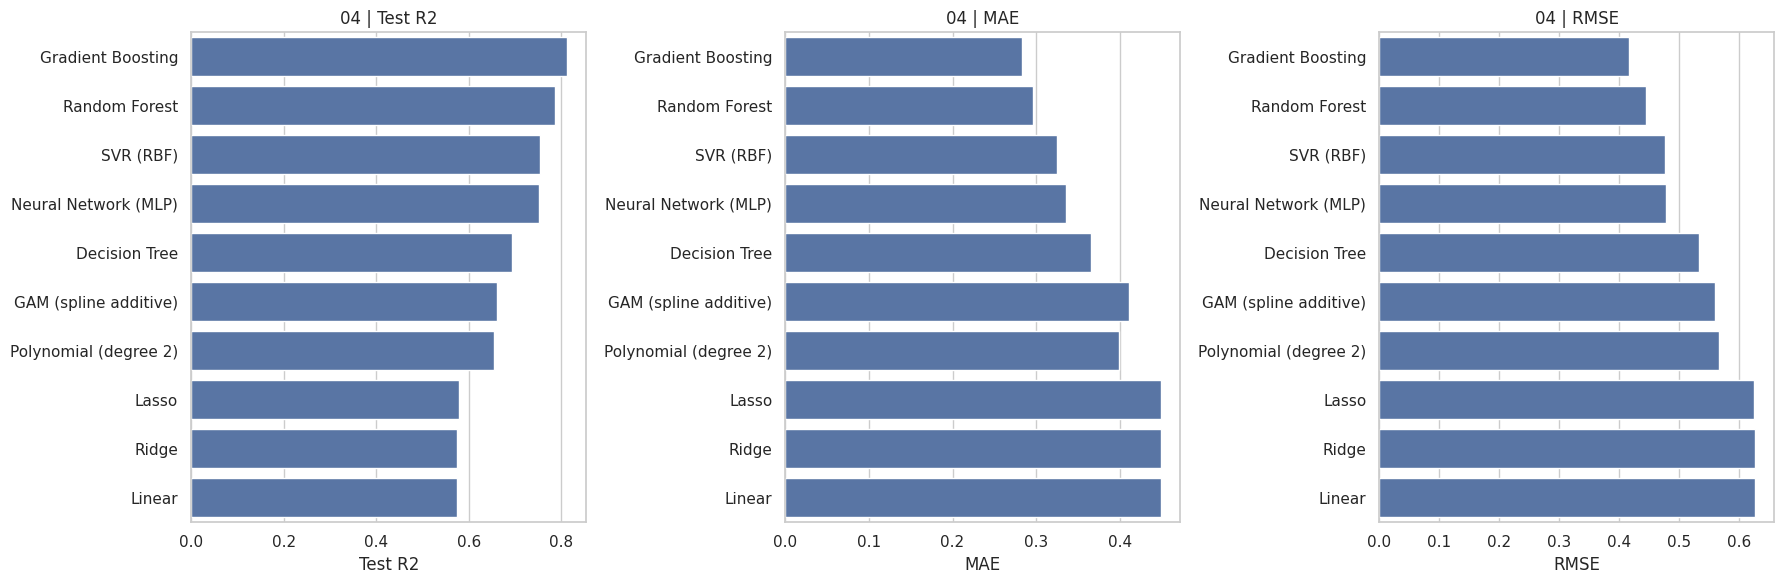

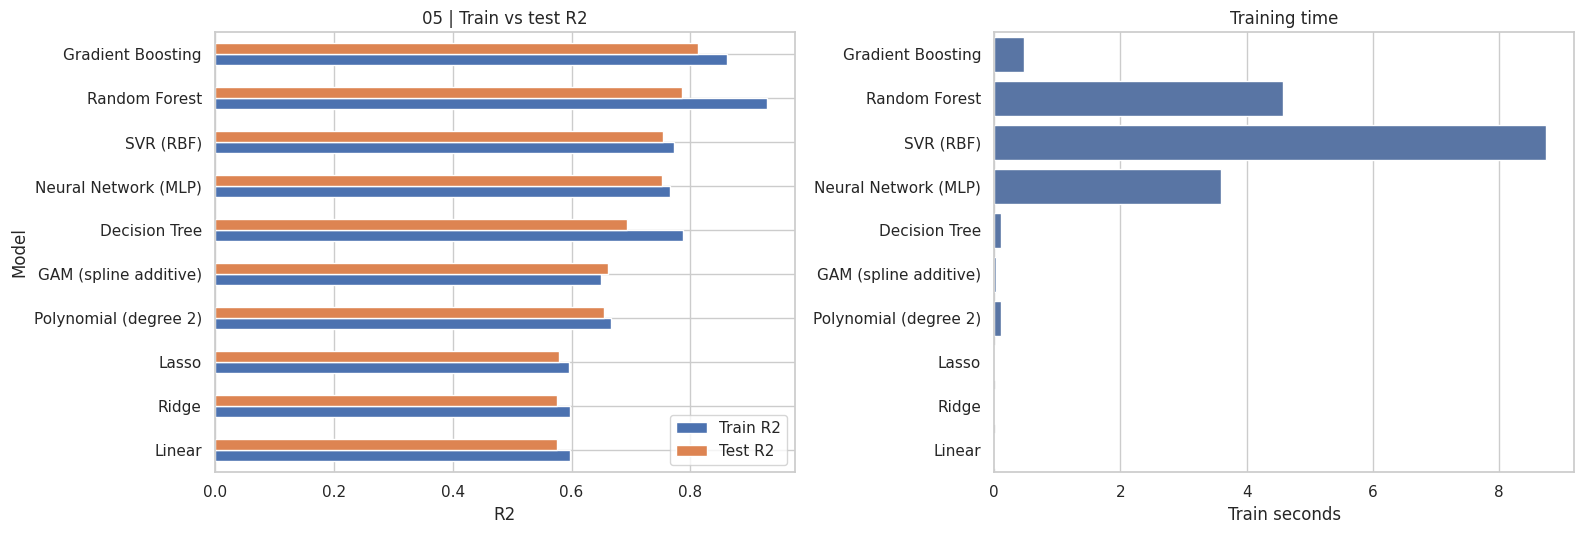

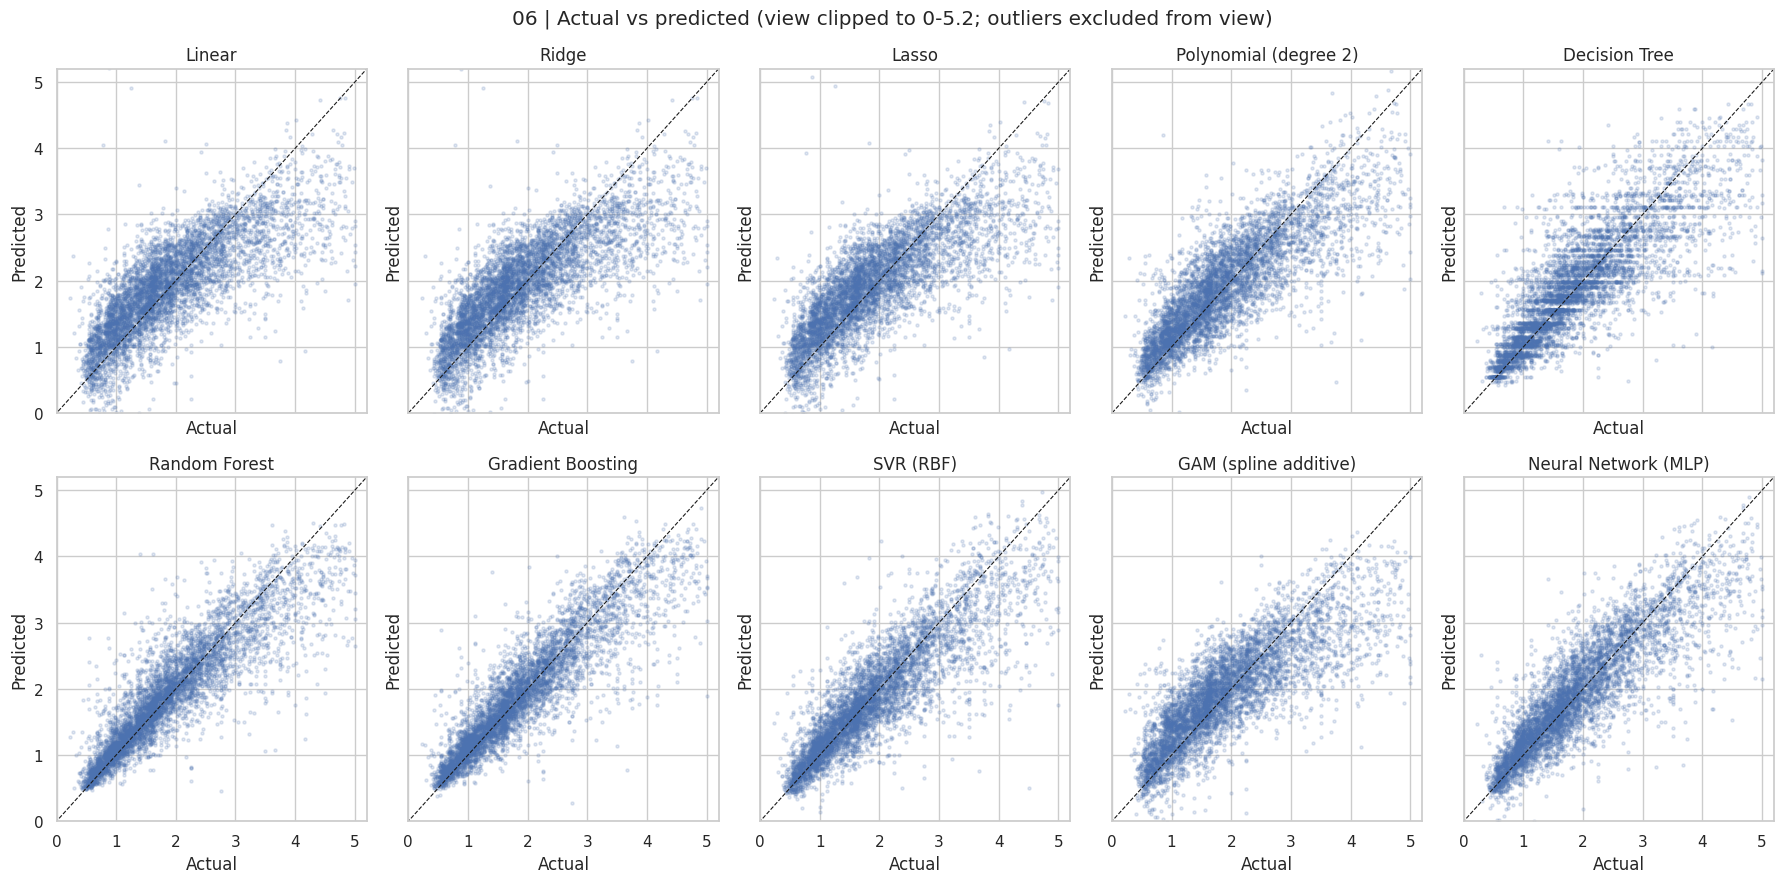

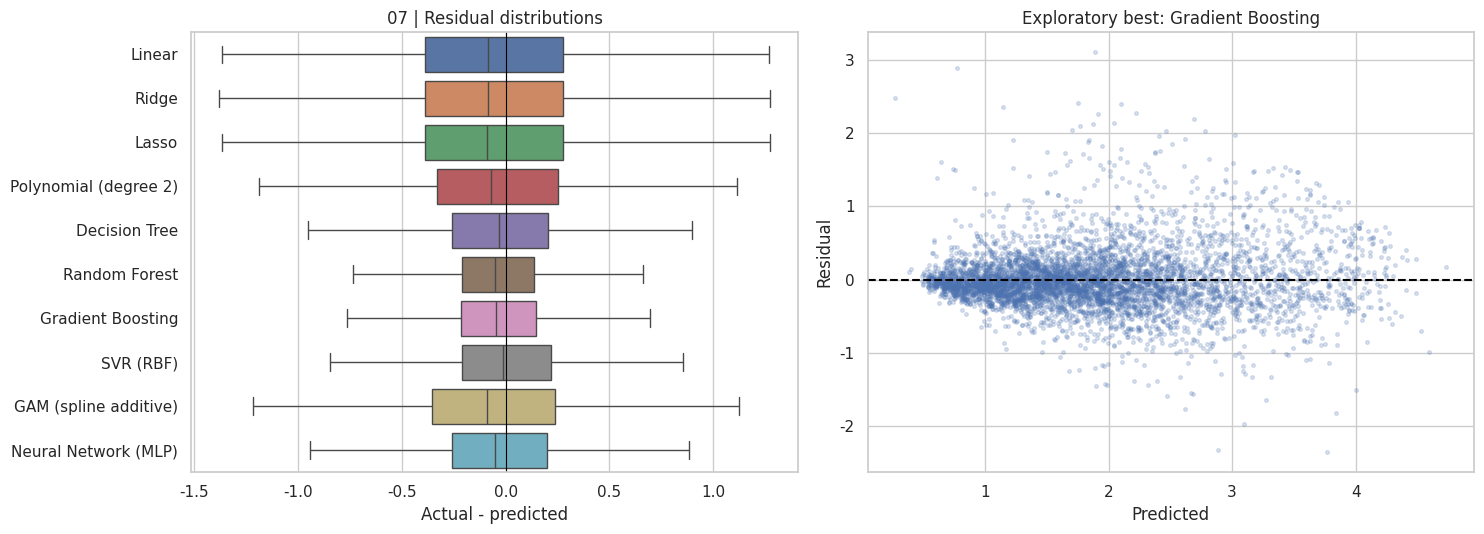

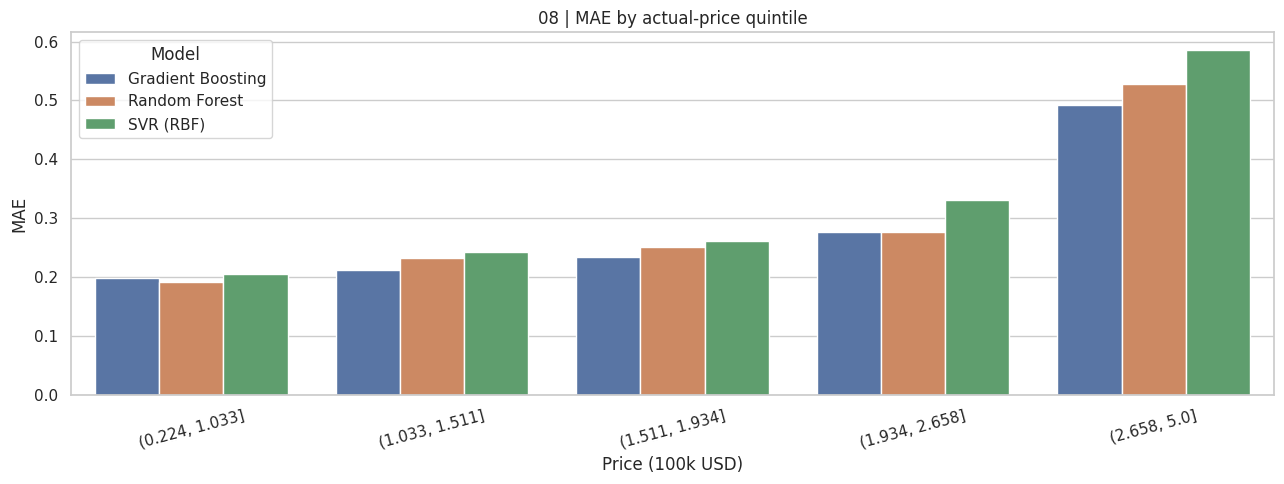

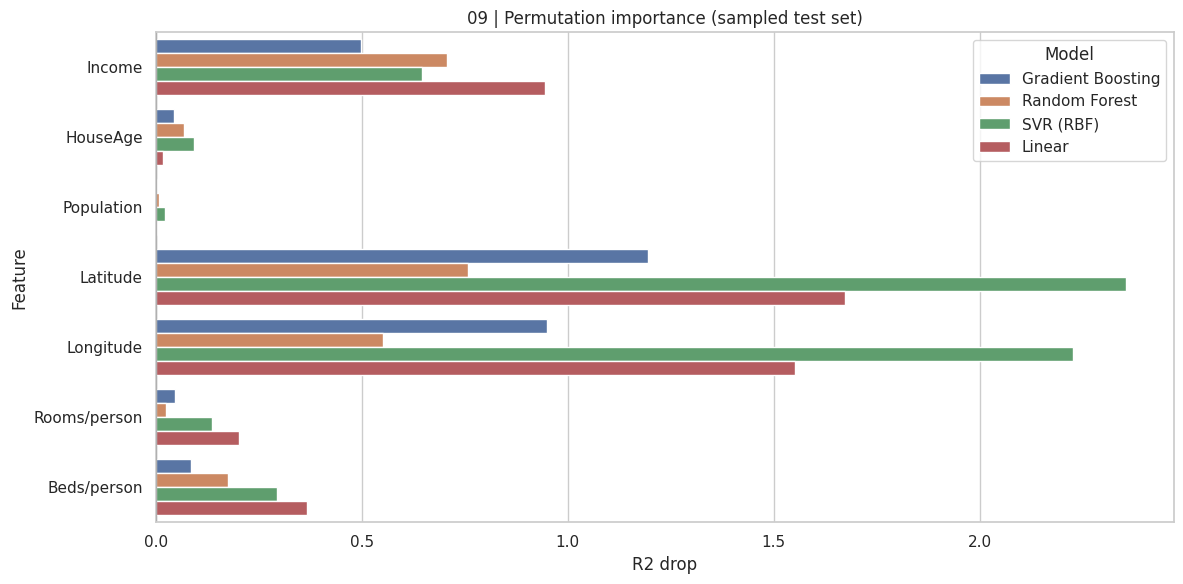

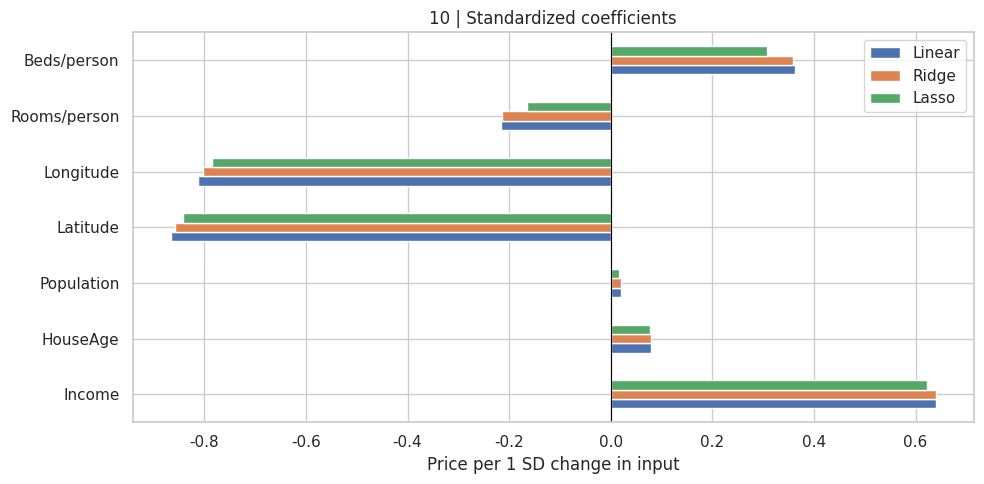

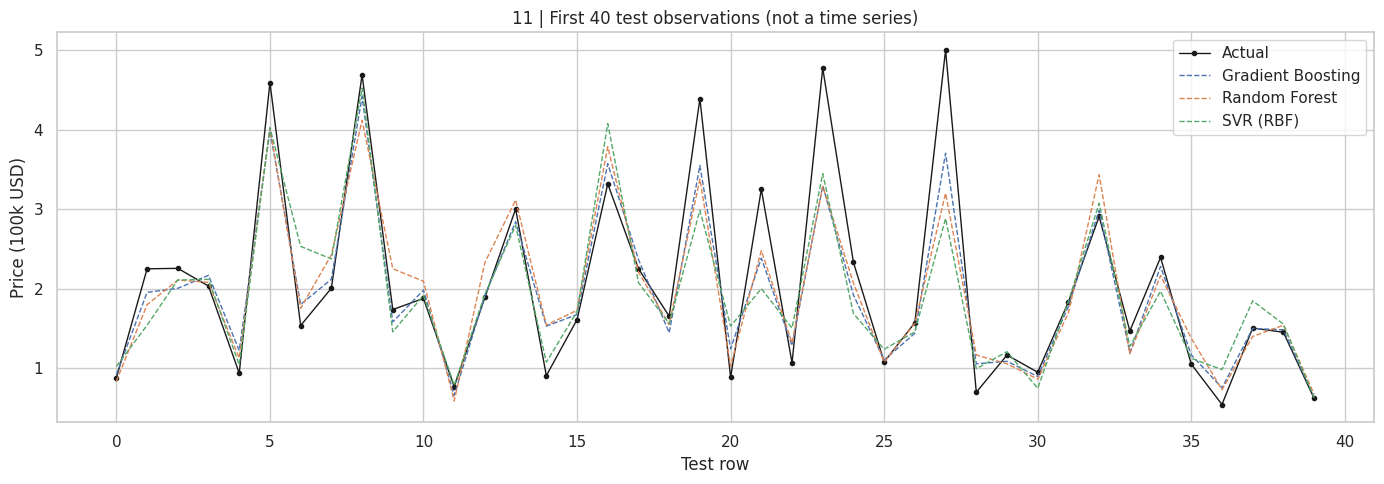

,Housing ID,Linear,Ridge,Lasso,Polynomial (degree 2),Decision Tree,Random Forest,Gradient Boosting,SVR (RBF),GAM (spline additive),Neural Network (MLP)
0,House 1,3.239,3.243,3.205,2.026,4.017,3.648,2.592,2.141,2.640,0.948
1,House 2,1.422,1.418,1.387,1.394,1.300,1.254,1.156,1.318,1.477,1.414
2,House 3,1.434,1.430,1.323,1.276,1.264,1.167,1.063,0.801,1.482,1.117


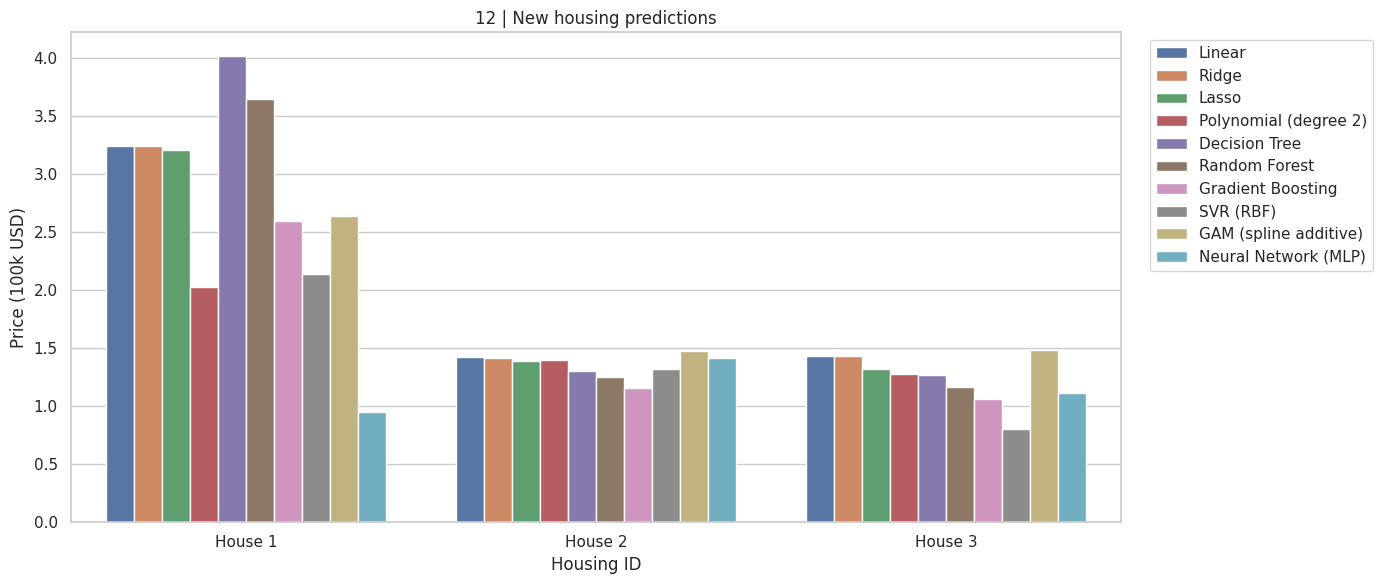

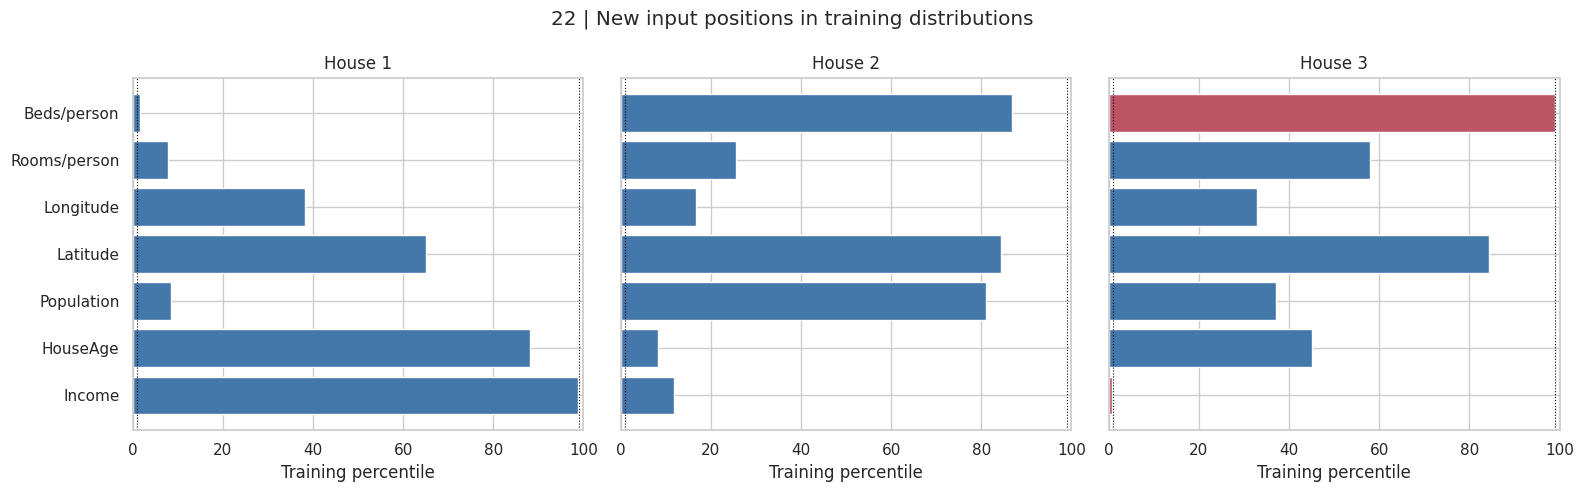

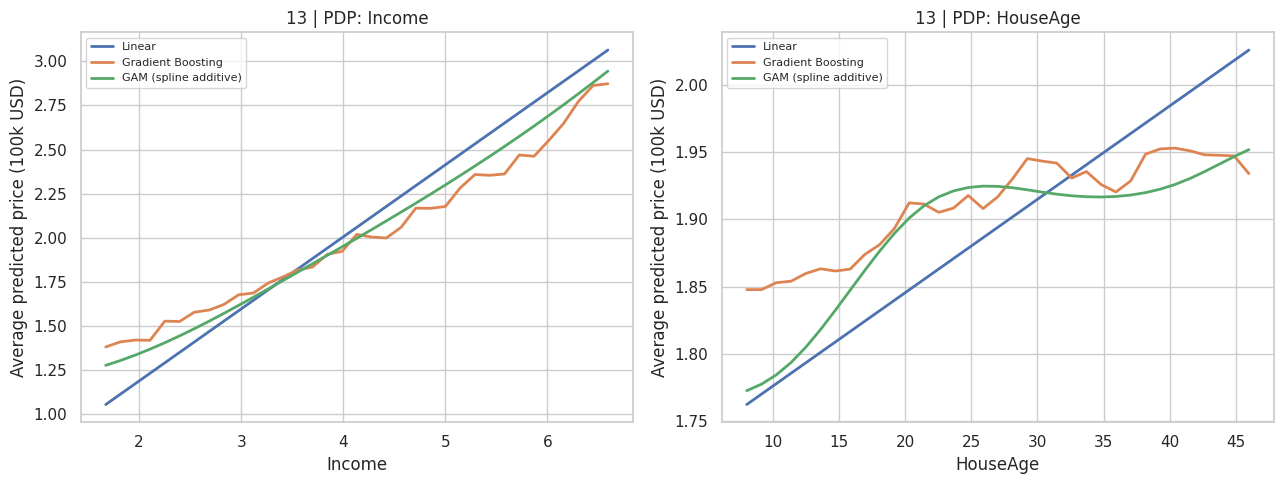

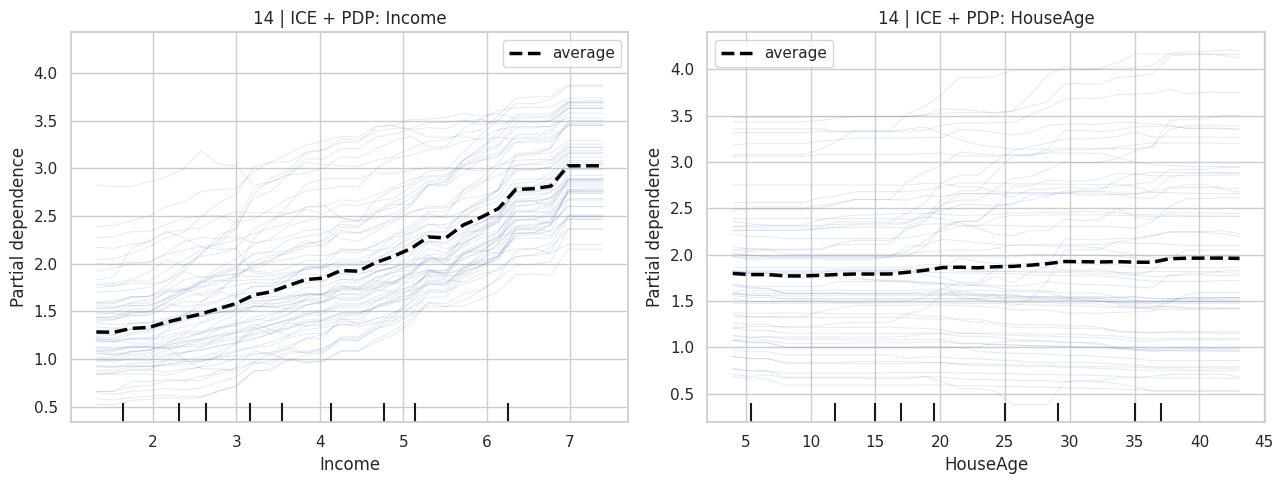

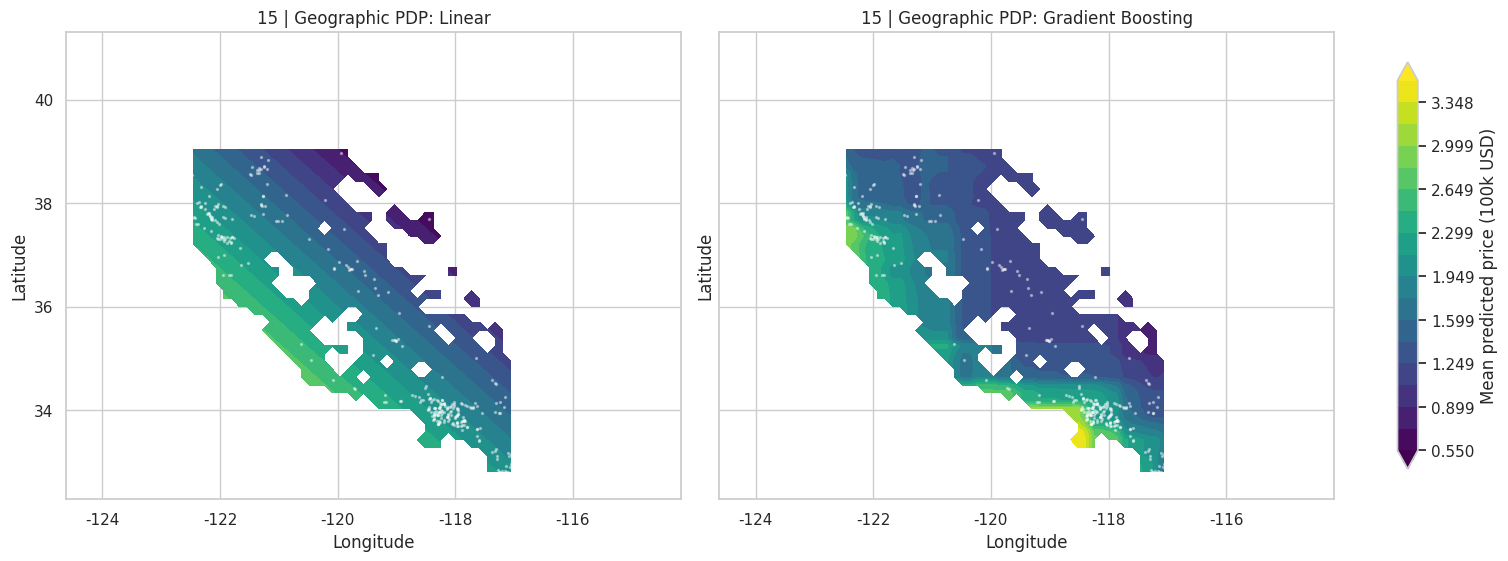

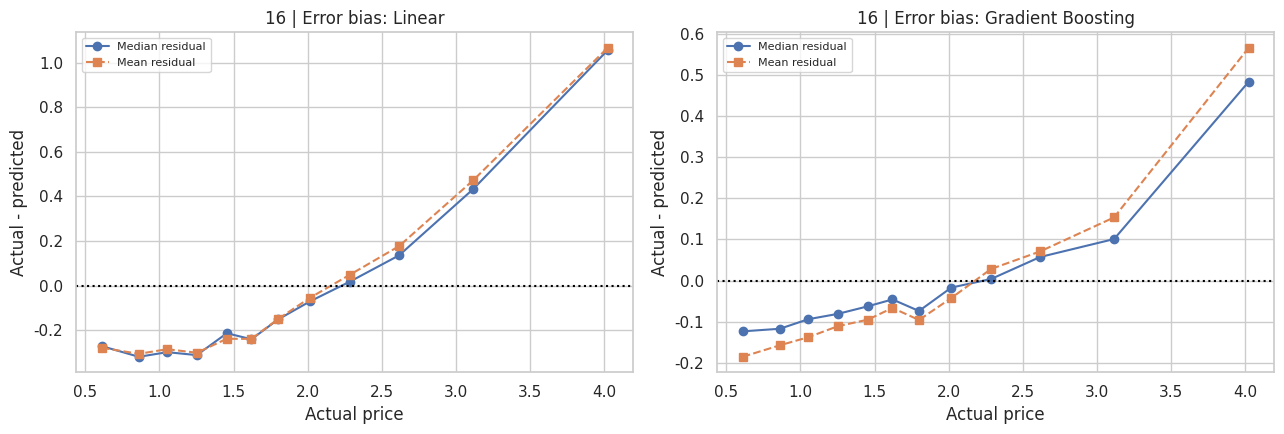

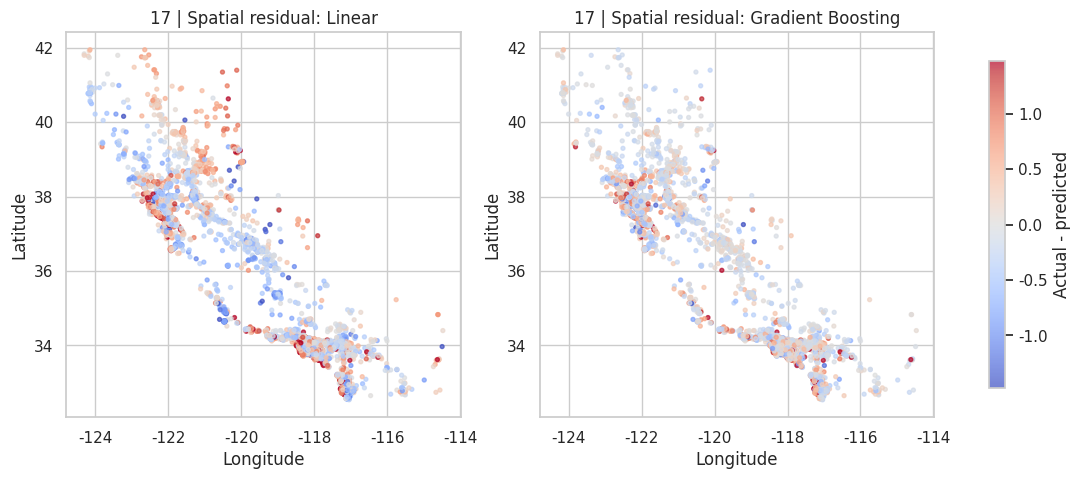

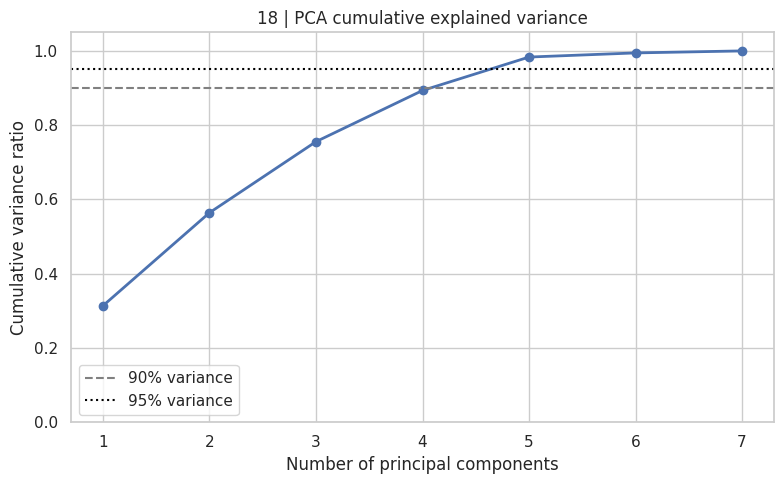

【内部検証で得た特徴量の暫定順位】 ['Latitude', 'Longitude', 'Income', 'Beds/person', 'Rooms/person', 'HouseAge', 'Population']


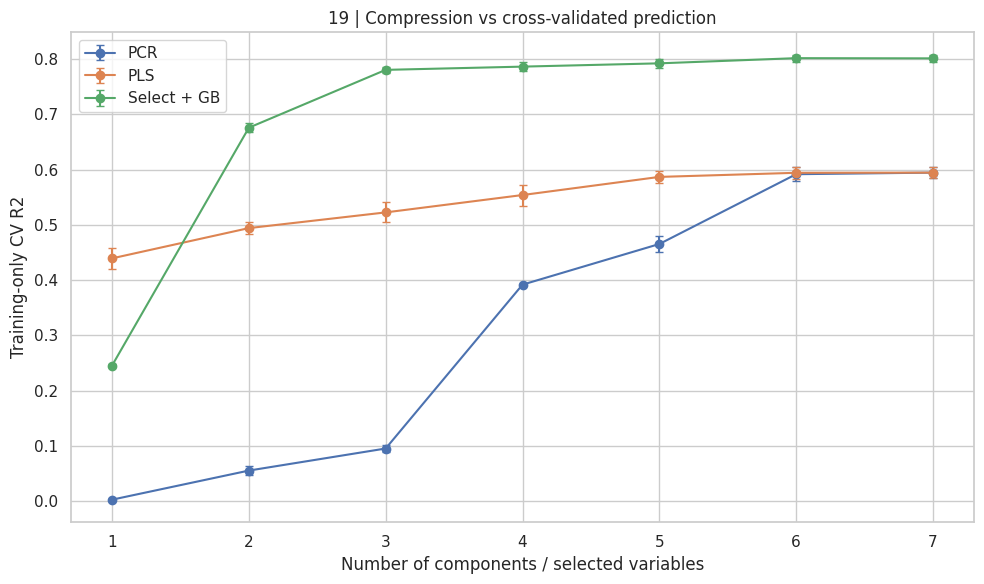

,Method,Dimensions,CV R2 mean,CV R2 std
0,PCR,1,0.0023,0.0006
1,PLS,1,0.4393,0.0187
2,Select + GB,1,0.2452,0.0023
3,PCR,2,0.0550,0.0076
4,PLS,2,0.4941,0.0102
5,Select + GB,2,0.6760,0.0084
6,PCR,3,0.0950,0.0065
7,PLS,3,0.5226,0.0181
8,Select + GB,3,0.7807,0.0060
9,PCR,4,0.3917,0.0009


【削減後の特徴量】 ['Latitude', 'Longitude', 'Income', 'Beds/person', 'Rooms/person']


,Model,Variables,Test R2,MAE
0,GB (all 7),7,0.8129,0.2826
1,GB (selected),5,0.8084,0.2864


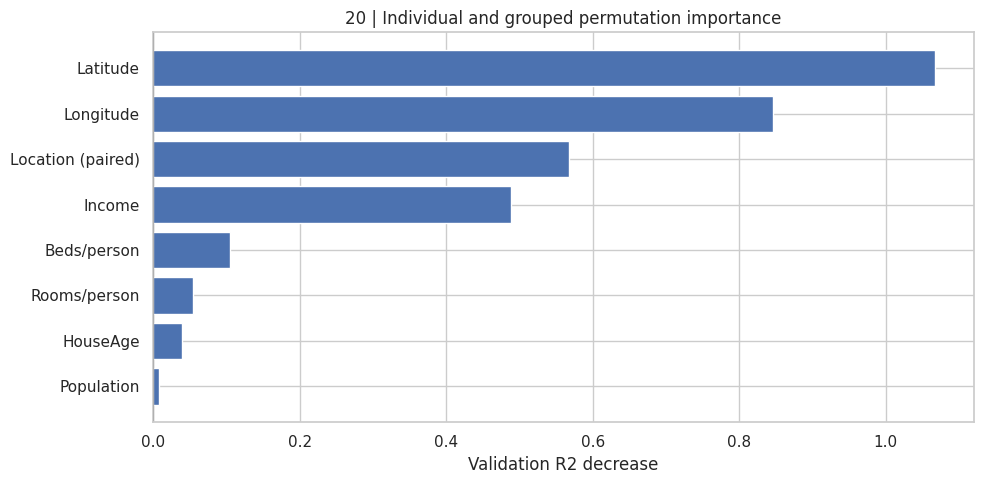

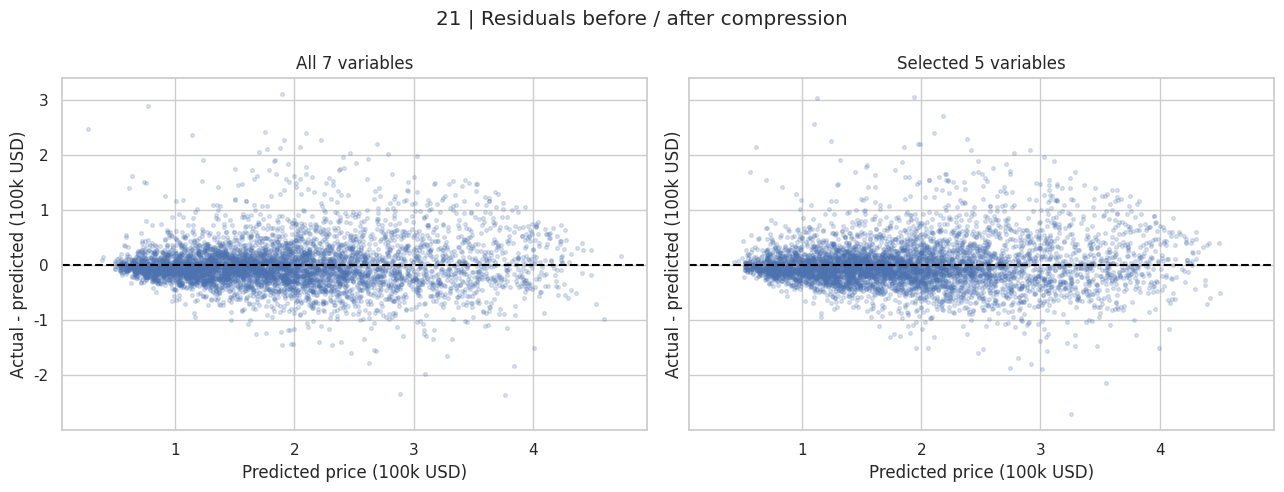

# 第9〜11章＋発展演習：住宅価格予測モデルの比較と考察

## 1. 目的と分析条件
1990年のカリフォルニア州のブロック単位の住宅データから価格（10万米ドル単位）を予測した。教材に従い、築年数52および住宅価格上限値5.00001に該当する行を順次除外し、18,572件を対象とした。7説明変数を用い、学習70%・テスト30%（random_state=0）の同一分割で10種類の回帰手法を比較した。各手法の設定は暫定値であり、最適化はしていない。

## 2. 予測性能の結果（図04〜08）
テストR²の最大は **Gradient Boosting（R²=0.813）** だった。基準の重回帰ではR²=0.575、Gradient BoostingではR²=0.813となった。MAEはそれぞれ0.449、0.283（10万米ドル単位）で、両者の差は37.1%であった。図06〜08では全体だけでなく、予測と実測の一致度、残差、価格帯ごとの誤差を確認できる。ただし同じテストセットで多数のモデルを比較して順位を決めているため、選ばれた最上位モデルの数値を独立な最終性能の推定とはみなせない。

## 3. 非線形モデルが有利になりうる理由（図03、13〜15）
所得・築年数のPDP（図13）は、説明変数を変えた際の平均的なモデル応答を示す。重回帰は直線的な応答しか表せないが、Gradient Boostingとスプライン加法モデルは曲線や閾値的変化を表現できる。ICE（図14）で住宅間の応答形状に違いが見られれば、他の変数との相互作用が存在する可能性を示す。位置に関する2次元PDP（図15）は、緯度と経度の組合せを評価する。樹木系モデルが空間的に異なる価格パターンを学習できることは、改善理由の一つとして考えられる。一方、PDPは非現実的な特徴量の組合せを作るため、単独で因果関係や真の地理効果を証明しない。

## 4. 誤差構造と不確実性（図07、08、16、17）
残差（実測−予測）の広がりや符号の偏りを観察し、価格帯別・地域別に系統的な誤差が残るかを確認する。高価格帯のMAEが大きい場合、全体平均の改善だけでは高価格住宅への適用を保証できない。また、新規3件のモデル間予測差（図12）は、予測の不一致を示すにとどまり、真の価格や適切な予測区間を直接示すものではない。

## 5. 特徴量重要度の解釈（図09、10）
線形モデルの標準化係数とPermutation Importanceは異なる量である。前者は条件付きの線形関係、後者は変数をシャッフルした際の予測性能の低下を表す。所得や位置情報が重要に見えても、因果効果とは結論できない。緯度・経度は強く関連するため、個別シャッフルの重要度は過大・過小評価され得る。

## 6. 情報を圧縮した際の予測性能と説明の明瞭さ（図18〜21）
PCAの累積寄与率（図18）は入力の分散をどの程度保持するかを示すが、住宅価格予測に必要な情報を保証しない。図19では内部検証データでPCR、PLS、元の特徴量を選んだGradient Boostingを比較した。少数変数モデルでは**5個**の元変数（緯度, 経度, 所得, 寝室数/人, 部屋数/人）を選択した。選択の条件は、内部検証R²の最高値から0.01以内の低下を許容し、使う変数の数を最小化することである。図20では単独の特徴量重要度と位置情報を組として変化させた重要度を示した。図21は全7変数と削減後のモデルの予測誤差を比較する。削減後のテストR²は0.808、元のGradient Boostingは0.813だった。単に次元数が少ないだけでなく、予測性能、保持した変数の意味、説明の安定性を併せて考える必要がある。なお重要度はモデルの予測応答を表し、因果効果ではない。

## 7. 新規住宅の入力分布（図12、22）
図22では新規入力が学習分布のどの分位にあるかを確認した。単一変数の分位点だけでは多変量的な外挿を判定できないが、モデル間で予測差が大きい物件の診断に役立つ。

## 8. 限界と次に行う検証
(1) 地理的近接性を考慮したSpatial/Group CV、(2) 学習データ内部でのハイパーパラメータ探索、(3) モデル選択と独立した最終テスト評価、(4) 価格上限の打切りの扱いと除外方針の感度分析、(5) 予測区間の校正が必要である。今回の結果は、対象データ・ランダム分割条件における探索的な比較であり、別地域・別時期にそのまま一般化できるとは限らない。


## 9. 研究としての検証設計
本結果に基づく次の問いは、地域を隔離しても性能が保たれるか、非線形な主効果だけで十分か、特徴量削減後の説明が別の標本でも安定するか、である。これらはモデル選択の際に学習データ内の検証で判断し、最後に独立テストで評価する。



【地域を分けた検証：モデルの外的妥当性】


Regional R2         Regional MAE        
                         mean     std         mean     std
Model                                                     
Gradient Boosting     -0.0688  0.1622       0.6812  0.1042
Linear                 0.3960  0.0901       0.4685  0.0337

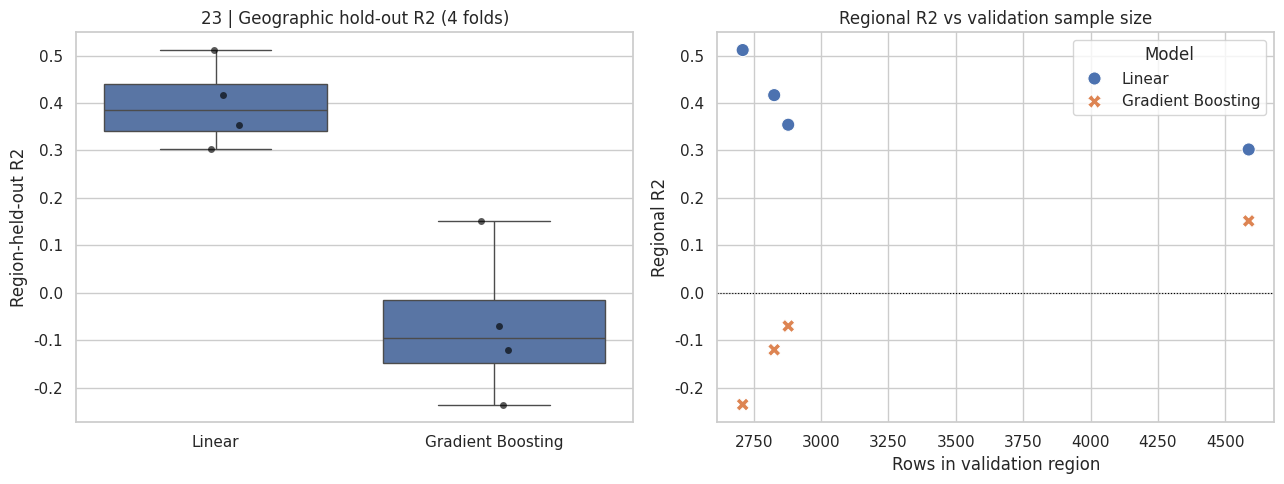

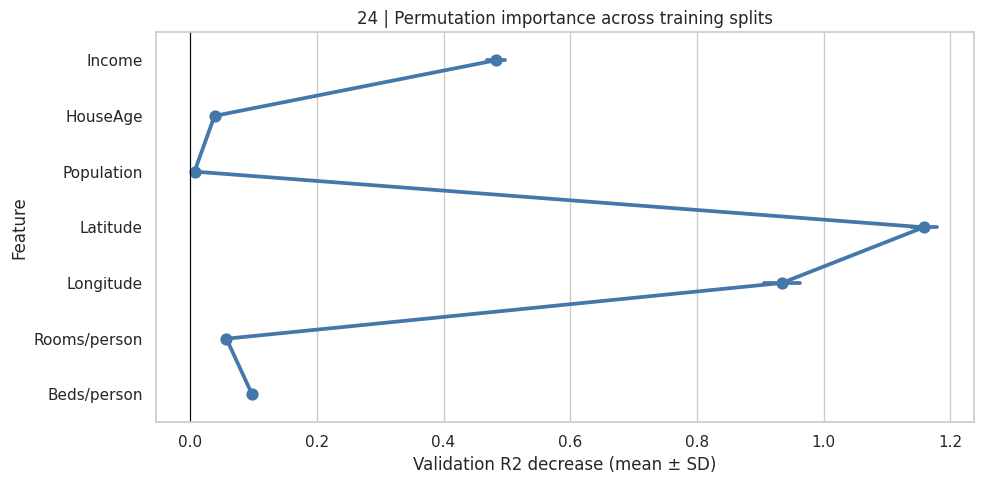


【学習ノート】


# データサイエンス学習ノート：結果から問いを立てる

## 1. 予測対象と外的妥当性
- 今回の分析対象：上限値を教材の手順で除外したカリフォルニア州のブロック単位データ。
- ランダム分割テストR²：Linear=0.575、Gradient Boosting=0.813。
- 地域をまとめて除外した4-fold平均R²：Linear=0.396、Gradient Boosting=-0.069。
- 問い：近傍の地域に使うのか、未観測地域に使うのか。検証条件は利用場面を模しているか。
- 注意：異なる検証設計のR²の差をモデル優劣の因果的証明とはしない。

## 2. 非線形性と相互作用
- Linear R²=0.575、GAM R²=0.661、Gradient Boosting R²=0.813。
- 非線形な「主効果」の導入だけでBoostingの性能差を全て説明できるか？
- 図13（PDP）、図14（ICE）、図15（2次元PDP）を見比べ、どの変数・組合せが重要そうかを仮説化する。
- 反証方法：緯度と経度の相互作用を明示したモデルを追加し、学習データ内CVで検証する。

## 3. 残差から次の特徴量を考える
- 図08・16：高価格側のMAEと系統的な過小予測が残るか。
- 図17：地域的な残差集中が残るか。
- 新たに得られるなら、交通アクセス、海岸距離、都市圏などを候補として検証する。
- 未取得の変数が必要でも「未取得」と明示し、推測値で埋めない。

## 4. 説明可能性と情報圧縮
- 図18（PCA）と図19（PCR・PLS・特徴量選択）は、同じ「次元削減」でも目的が違う。
- 今回の少数変数候補：緯度, 経度, 所得, 寝室数/人, 部屋数/人（5変数）。
- 選択規則は内部CVで全7変数からR²低下0.01以内の最小次元。最終的な有効性を保証しない。
- 図20：緯度・経度を同時に入れ替えたときの重要度を個別と区別する。
- 図24：データを分け直した時に重要度順位が安定するか。

## 5. 個別予測と分布外入力
- 図12：House 1の予測がモデルにより大きく割れる理由を問いにする。
- 図22：各変数の学習分位点を確認。ただし単一変数が正常範囲でも、
  相互に不自然な組合せは生じ得る。
- モデル間予測値のばらつきを、そのまま予測区間や確率とみなさない。

## 6. 分析者としての自己チェック
- [ ] 学習用途・将来の使用対象を先に定義したか。
- [ ] 上限値を削除した場合、何を予測するモデルになるか説明できるか。
- [ ] 前処理・標準化・特徴量選択を検証fold内だけで学習しているか。
- [ ] テストデータを繰り返し見た結果でチューニングしていないか。
- [ ] 少なくとも地域別・価格帯別の失敗例を確認したか。
- [ ] PDP・重要度・係数を因果効果として説明していないか。
- [ ] 圧縮後に失う情報とモデルの不安定性を確認したか。
- [ ] 「この分析から言えること／まだ言えないこと」を分けているか。


【完了】10モデル比較・提出用考察保存。図 24枚
housing_report_discussion.md / housing_10model_comparison.csv / housing_10model_new_predictions.csv
housing_dimension_comparison.csv / housing_compact_model_comparison.csv
housing_regional_validation.csv / housing_importance_stability.csv / housing_learning_notes.md
画像ZIP: /content/housing_figures_10models.zip


In [7]:
# ================================================================
# 第9〜11章＋発展演習｜10回帰手法・非線形性の可視化・考察レポート
# Google Colab：このセルを1回実行／CSVアップロード不要
# ================================================================
# 目的：①前処理 ②10モデル比較 ③誤差診断 ④PDP・ICE・相互作用分析
#       ⑤提出用の考察（Markdown）を、計算結果から自動生成する。
# 注意：テストデータは固定。今回の性能順位は探索的比較であり、
#       同じテスト結果に基づくモデル選択後の「最終汎化性能」ではない。
#       因果推論ではなく、予測と関連性の分析である。
import time, warnings, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, SplineTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance, PartialDependenceDisplay, partial_dependence
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.base import clone

# 設定：SHOW_FIGURES=Falseなら画像は保存のみ（Colab出力の省略を回避）。
SEED, TEST_SIZE = 0, 0.30
SHOW_FIGURES = True
FIG_DIR = Path('/content/housing_figures_10models') if Path('/content').exists() else Path('housing_figures_10models')
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
# 図の中は英語表記に統一し、Colab標準フォントでの日本語欠落を防ぐ。
# データフレームの日本語列名・Markdownレポートの日本語は維持する。
plt.rcParams['axes.unicode_minus'] = False

def save_plot(filename):
    """図をPNG保存し、表示設定に応じて画面に出す。"""
    # Axes textだけを英語に置換（元の日本語DataFrame列名は変更しない）。
    for axis in plt.gcf().axes:
        axis.set_xlabel(en.get(axis.get_xlabel(), axis.get_xlabel()) if 'en' in globals() else axis.get_xlabel())
        axis.set_ylabel(en.get(axis.get_ylabel(), axis.get_ylabel()) if 'en' in globals() else axis.get_ylabel())
        axis.set_title(str(axis.get_title()).replace('所得','Income').replace('築年数','HouseAge').replace('緯度','Latitude').replace('経度','Longitude'))
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=150, bbox_inches='tight')
    if SHOW_FIGURES: plt.show()
    else: plt.close()


# ================================================================
# 学習の進め方：データサイエンティストの思考プロセス
# ================================================================
# [問い] 何を・誰に対して予測するのか（対象母集団、利用場面、損失）？
# [仮説] 線形性、相互作用、地域の近接、情報重複の何が効いているか？
# [設計] データ分割、前処理、基準モデル、交差検証を先に決める。
# [検証] 平均R²だけでなく、地域・価格帯・外れ値で残差を見る。
# [説明] PDP/ICE/Permutation重要度は「モデルの応答」であって因果ではない。
# [反証] 仮説と逆の結果が出たら、分割方法・交絡・設定を再点検する。
# [判断] 精度、簡潔さ、説明の忠実度、適用範囲を合わせて選ぶ。
#
# 重要：この教材では同じテストセットで10モデルを探索的に比較する。
#      ここでの1位のR²は、厳密な独立最終評価値ではない。
#      新しいモデルや設定を試す判断は学習側の交差検証で行う。
# ================================================================

# ─────────────────────────────────────────
# 9章：取得・前処理（教材の操作を再現）
# ─────────────────────────────────────────
raw = fetch_california_housing(as_frame=True)
rename = {'MedInc':'所得','HouseAge':'築年数','AveRooms':'部屋数',
          'AveBedrms':'寝室数','Population':'地域人口','AveOccup':'世帯人数',
          'Latitude':'緯度','Longitude':'経度'}
df_raw = raw.data.rename(columns=rename).copy()
df_raw['住宅価格'] = raw.target.to_numpy()  # 10万米ドル単位
# 上限に集約された観測を教材に従って削除。誤記とは断定しない。
age_mask = df_raw['築年数'].eq(52)
df_age = df_raw.loc[~age_mask].copy()
price_mask = np.isclose(df_age['住宅価格'], 5.00001, atol=1e-8, rtol=0)
df = df_age.loc[~price_mask].copy()
# （部屋/世帯）÷（人口/世帯）＝部屋/人。0除算は欠損として扱う。
occup = df['世帯人数'].replace(0, np.nan)
df['部屋数/人'] = df['部屋数']/occup
df['寝室数/人'] = df['寝室数']/occup
features = ['所得','築年数','地域人口','緯度','経度','部屋数/人','寝室数/人']
labels = ['Income','HouseAge','Population','Latitude','Longitude','Rooms/person','Beds/person']
en = dict(zip(features, labels))
df = df[features+['住宅価格']].replace([np.inf,-np.inf],np.nan).dropna()
print(f'【9章】元データ {df_raw.shape} → 前処理後 {df.shape} ／ 築年数除外 {age_mask.sum()} ／ 価格上限除外 {price_mask.sum()}')
if df.shape != (18572,8): warnings.warn('教材の期待値(18572,8)と異なります。')
display(df.head())
df.to_csv('california_housing_cleansing.csv',index=False,encoding='utf-8-sig')

# 図01：変数の分布。外れ値、裾の長さ、スケールの違いを確認。
fig,axes=plt.subplots(2,4,figsize=(16,7))
for ax,col,lab in zip(axes.flat,features+['住宅価格'],labels+['Price']):
    sns.histplot(df[col],bins=40,ax=ax)
    ax.set(xlabel=lab,ylabel='Count')
fig.suptitle('01 | Cleaned distributions'); save_plot('01_distributions.png')
# 図02：削除件数と対象（住宅価格）の分布変化。
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
axes[0].bar(['Raw','Age removed','Price removed','Cleaned'],[len(df_raw),age_mask.sum(),price_mask.sum(),len(df)])
axes[0].set(title='02 | Cleaning counts',ylabel='Rows')
sns.histplot(df_raw['住宅価格'],bins=45,stat='density',alpha=.4,label='Raw',ax=axes[1])
sns.histplot(df['住宅価格'],bins=45,stat='density',alpha=.4,label='Cleaned',ax=axes[1])
axes[1].legend(); axes[1].set(xlabel='Price (100k USD)',title='Target distribution')
save_plot('02_cleaning.png')
# 【考える】経度と価格の単相関が小さくても、なぜ経度が予測に重要になりうる？
# → 地域の条件付き効果（緯度×経度）を単相関1個では表現できない。
# → ただし相関係数だけで交互作用の存在を証明できない。
# 図03：住宅価格の地域差と相関行列。相関≠因果。
fig,axes=plt.subplots(1,2,figsize=(14,5.2))
sc=axes[0].scatter(df['経度'],df['緯度'],c=df['住宅価格'],s=5,alpha=.65,cmap='viridis',rasterized=True)
fig.colorbar(sc,ax=axes[0],label='Price (100k USD)')
axes[0].set(xlabel='Longitude',ylabel='Latitude',title='03 | Geography and price')
sns.heatmap(df[features+['住宅価格']].corr(),vmin=-1,vmax=1,center=0,cmap='coolwarm',
            xticklabels=labels+['Price'],yticklabels=labels+['Price'],annot=True,fmt='.1f',ax=axes[1])
axes[1].set_title('Correlations'); save_plot('03_geography_correlations.png')

# ─────────────────────────────────────────
# 10〜11章：学習と比較。Scalerは学習側だけでfitする。
# ─────────────────────────────────────────
X,y=df[features],df['住宅価格']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=TEST_SIZE,random_state=SEED)
# GAM近似：各説明変数に別々のスプライン基底を作る加法回帰。
# 通常のGAM専用推定器（pyGAM等）とは実装・平滑化選択が異なる。
gam_transform=ColumnTransformer([(f'spline_{i}',SplineTransformer(n_knots=6,degree=3,include_bias=False),[c])
                                 for i,c in enumerate(features)])
models={
 'Linear':make_pipeline(StandardScaler(),LinearRegression()),
 'Ridge':make_pipeline(StandardScaler(),Ridge(alpha=10.0)),
 'Lasso':make_pipeline(StandardScaler(),Lasso(alpha=.003,max_iter=15000)),
 'Polynomial (degree 2)':make_pipeline(StandardScaler(),PolynomialFeatures(degree=2,include_bias=False),Ridge(alpha=10.0)),
 'Decision Tree':DecisionTreeRegressor(max_depth=10,min_samples_leaf=8,random_state=SEED),
 'Random Forest':RandomForestRegressor(n_estimators=100,min_samples_leaf=3,n_jobs=-1,random_state=SEED),
 'Gradient Boosting':HistGradientBoostingRegressor(max_iter=200,learning_rate=.05,random_state=SEED),
 'SVR (RBF)':make_pipeline(StandardScaler(),SVR(C=10,epsilon=.1,gamma='scale',cache_size=500)),
 'GAM (spline additive)':make_pipeline(gam_transform,Ridge(alpha=10.0)),
 'Neural Network (MLP)':make_pipeline(StandardScaler(),MLPRegressor(hidden_layer_sizes=(64,32),early_stopping=True,max_iter=400,random_state=SEED)),
}
records,fitted,preds=[],{},{}
for name,model in models.items():
    t0=time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(X_train,y_train)
    elapsed=time.perf_counter()-t0
    pred=model.predict(X_test)
    fitted[name],preds[name]=model,pred
    records.append({'Model':name,'Train R2':r2_score(y_train,model.predict(X_train)),
                    'Test R2':r2_score(y_test,pred),'MAE':mean_absolute_error(y_test,pred),
                    'RMSE':np.sqrt(mean_squared_error(y_test,pred)),'Train seconds':elapsed})
    print(f'{name:24s}: test R²={records[-1]["Test R2"]:.3f} ／ {elapsed:.1f} sec'
          + (f' ／ warnings={len(caught)}' if caught else ''))
result_df=pd.DataFrame(records).sort_values('Test R2',ascending=False).reset_index(drop=True)
display(result_df.round(4))
result_df.to_csv('housing_10model_comparison.csv',index=False,encoding='utf-8-sig')
ytrue=y_test.to_numpy()
# 注：以下の「best」は一度見たテスト結果で選んでいる。探索的な図示に限る。
best_name=result_df.iloc[0]['Model']; best=fitted[best_name]
top3=result_df['Model'].head(3).tolist()

# 図04：R²は大きいほど、MAE・RMSEは小さいほど良い。
fig,axes=plt.subplots(1,3,figsize=(18,6))
for ax,metric in zip(axes,['Test R2','MAE','RMSE']):
    sns.barplot(data=result_df,y='Model',x=metric,ax=ax)
    ax.set(title=f'04 | {metric}',ylabel='')
save_plot('04_ten_model_metrics.png')
# 図05：学習/テストの乖離を過学習の手掛かりとして見る。学習時間は環境依存。
fig,axes=plt.subplots(1,2,figsize=(16,5.5))
result_df.set_index('Model')[['Train R2','Test R2']].sort_values('Test R2').plot.barh(ax=axes[0])
axes[0].set(title='05 | Train vs test R2',xlabel='R2')
sns.barplot(data=result_df,y='Model',x='Train seconds',ax=axes[1])
axes[1].set(title='Training time',ylabel='')
save_plot('05_fit_gap_and_time.png')
# 図06：対角線に近いほど予測が正確。軸範囲をモデル間で統一。
fig,axes=plt.subplots(2,5,figsize=(18,9),sharex=True,sharey=True)
lim=(min(ytrue.min(),*(v.min() for v in preds.values())),max(ytrue.max(),*(v.max() for v in preds.values())))
for ax,(name,p) in zip(axes.flat,preds.items()):
    ax.scatter(ytrue,p,s=5,alpha=.17,rasterized=True)
    ax.plot(lim,lim,'k--',lw=.8)
    ax.set(title=name, xlim=(0,5.2), ylim=(0,5.2), xlabel='Actual', ylabel='Predicted')
fig.suptitle('06 | Actual vs predicted (view clipped to 0-5.2; outliers excluded from view)'); save_plot('06_actual_predicted_all.png')
# 図07：残差（実測−予測）の幅と系統性。箱ひげの外れ値は描画のみ省略。
fig,axes=plt.subplots(1,2,figsize=(15,5.5))
residuals=pd.DataFrame({n:ytrue-p for n,p in preds.items()})
sns.boxplot(data=residuals,orient='h',showfliers=False,ax=axes[0])
axes[0].axvline(0,color='black',lw=.8)
axes[0].set(title='07 | Residual distributions',xlabel='Actual - predicted')
axes[1].scatter(preds[best_name],ytrue-preds[best_name],s=7,alpha=.2,rasterized=True)
axes[1].axhline(0,color='black',ls='--')
axes[1].set(title=f'Exploratory best: {best_name}',xlabel='Predicted',ylabel='Residual')
save_plot('07_residuals.png')
# 【考える】全体MAEだけで「高価格の住宅でも使える」と言えるか？
# → 価格帯別の絶対誤差・相対誤差・過大/過小予測の符号を併記したい。
# → 実測価格で層別した残差には条件付けによる傾向も出るため、
#    予測値で層別した残差や地域別残差でも確認する。
# 図08：価格5分位別MAE。高価格帯で誤差が増えるかを見る。
bands=pd.qcut(pd.Series(ytrue),q=5,duplicates='drop')
band_rows=[]
for name in top3:
    for band in bands.cat.categories:
        mask=(bands==band).to_numpy()
        band_rows.append({'Model':name,'Price band':str(band),'MAE':np.abs(ytrue[mask]-preds[name][mask]).mean()})
fig,ax=plt.subplots(figsize=(13,5))
sns.barplot(data=pd.DataFrame(band_rows),x='Price band',y='MAE',hue='Model',ax=ax)
ax.tick_params(axis='x',rotation=15)
ax.set(title='08 | MAE by actual-price quintile',xlabel='Price (100k USD)')
save_plot('08_error_by_price_band.png')
# 図09：特徴量を1つシャッフルしたときのR²低下（因果的寄与ではない）。
# 相関のある特徴量は重要度が歪みうる。テストを図示に使っている点にも注意。
X_imp=X_test.sample(n=min(1000,len(X_test)),random_state=SEED)
y_imp=y_test.loc[X_imp.index]
perm_rows=[]
for name in dict.fromkeys(top3+['Linear']):
    imp=permutation_importance(fitted[name],X_imp,y_imp,n_repeats=3,random_state=SEED,scoring='r2')
    for i,label in enumerate(labels):
        perm_rows.append({'Model':name,'Feature':label,'R2 drop':imp.importances_mean[i]})
fig,ax=plt.subplots(figsize=(12,6))
sns.barplot(data=pd.DataFrame(perm_rows),x='R2 drop',y='Feature',hue='Model',ax=ax)
ax.axvline(0,color='black',lw=.8)
ax.set(title='09 | Permutation importance (sampled test set)')
save_plot('09_feature_importance.png')
# 図10：標準化したLinear・Ridge・Lassoの係数（係数≠因果効果）。
coef=pd.DataFrame({n:fitted[n].steps[-1][1].coef_ for n in ['Linear','Ridge','Lasso']},index=labels)
fig,ax=plt.subplots(figsize=(10,5))
coef.plot.barh(ax=ax); ax.axvline(0,color='black',lw=.8)
ax.set(title='10 | Standardized coefficients',xlabel='Price per 1 SD change in input')
save_plot('10_linear_coefficients.png')
# 図11：テスト行の先頭40件。横軸は「時間」ではない。
fig,ax=plt.subplots(figsize=(14,5))
ix=np.arange(min(40,len(ytrue)))
ax.plot(ix,ytrue[:len(ix)],'ko-',lw=1,ms=3,label='Actual')
for name in top3: ax.plot(ix,preds[name][:len(ix)],'--',lw=1,label=name)
ax.set(title='11 | First 40 test observations (not a time series)',xlabel='Test row',ylabel='Price (100k USD)')
ax.legend(); save_plot('11_first_40.png')
# 図12：新規3件の全モデル予測。正解価格は不明のため「当たり外れ」は判定できない。
X_new=pd.DataFrame([[8,41,500,37,-120,1,.2],[2,10,2000,38,-122,1.5,.5],
                    [1,25,1000,38,-121,2,1]],columns=features)
newpred=pd.DataFrame({'Housing ID':['House 1','House 2','House 3']})
for name,model in fitted.items(): newpred[name]=model.predict(X_new)
display(newpred.round(3))
newpred.to_csv('housing_10model_new_predictions.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(14,6))
sns.barplot(data=newpred.melt(id_vars='Housing ID',var_name='Model',value_name='Price'),x='Housing ID',y='Price',hue='Model',ax=ax)
ax.legend(bbox_to_anchor=(1.02,1),loc='upper left')
ax.set(title='12 | New housing predictions',ylabel='Price (100k USD)')
save_plot('12_new_predictions.png')


# 図22：入力の外挿性を診断。新規3件について訓練分布の1〜99%範囲を表示する。
# 実測正解のない新規物件でモデル間予測が割れる理由を検証するための補助図。
fig,axes=plt.subplots(1,3,figsize=(16,5),sharey=True)
for ax,(i,house) in zip(axes,X_new.iterrows()):
    percentiles=[100*(X_train[c] <= house[c]).mean() for c in features]
    ax.barh(labels,percentiles,color=['#bb5566' if (p<1 or p>99) else '#4477aa' for p in percentiles])
    ax.axvline(1,color='black',ls=':',lw=.8); ax.axvline(99,color='black',ls=':',lw=.8)
    ax.set(xlim=(0,100),xlabel='Training percentile',title=f'House {i+1}')
fig.suptitle('22 | New input positions in training distributions')
save_plot('22_new_input_percentiles.png')

# ─────────────────────────────────────────
# 発展①：非線形性を「直接」可視化する
# ─────────────────────────────────────────
# PDP: ある変数を固定値にして、他変数は観測分布に沿って平均した予測。
# ICE: 同様の操作を各住宅ごとに描いた線。個体差・相互作用の手掛かり。
# 注意：相関特徴量を非現実的な組合せに固定する危険がある。
# 【仮説】重回帰の性能が低いのは線形性の仮定が強すぎるためか？
# → GAM（非線形主効果あり、相互作用なし）とBoostingを比較する。
# → 曲線の違いだけで性能差の原因を確定しない。学習条件や交互作用も検証。
# 図13：所得・築年数のPDP比較。直線（Linear）vs 曲線（Boosting）。
# 推定結果は入力分布の端で不安定になり得るため5〜95パーセンタイルに制限。
X_explain=X_train.sample(n=min(700,len(X_train)),random_state=SEED)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax, f in zip(axes, ['所得', '築年数']):
    for name in ['Linear', 'Gradient Boosting', 'GAM (spline additive)']:
        # from_estimator() は描画済みAxesへの再描画を禁止する場合がある。
        # そのためPDPの計算と描画を分離し、同一Axesにax.plot()で重ねる。
        # method='brute'：X_explainの他の説明変数を維持して平均予測を計算。
        pd_result = partial_dependence(
            estimator=fitted[name], X=X_explain, features=[f],
            method='brute', kind='average',
            percentiles=(0.05, 0.95), grid_resolution=35
        )
        # scikit-learnの新旧バージョン両方に対応。
        grid_key = 'grid_values' if 'grid_values' in pd_result else 'values'
        grid = pd_result[grid_key][0]
        average_prediction = pd_result['average'][0]
        ax.plot(grid, average_prediction, linewidth=2, label=name)
    ax.set_title(f'13 | PDP: {en[f]}')
    ax.set_xlabel(en[f])
    ax.set_ylabel('Average predicted price (100k USD)')
    ax.legend(fontsize=8)
save_plot('13_pdp_income_age.png')
# 図14：ICE（薄線）と平均PDP（太線）。ICEの個体差は相互作用の兆候。
# 薄線同士の縦方向の差だけでは相互作用の証拠にはならない。
fig,axes=plt.subplots(1,2,figsize=(13,5))
X_ice=X_train.sample(n=min(70,len(X_train)),random_state=SEED)
for ax,f in zip(axes,['所得','築年数']):
    PartialDependenceDisplay.from_estimator(fitted['Gradient Boosting'],X_ice,[f],
        kind='both',subsample=60,random_state=SEED,percentiles=(.05,.95),
        grid_resolution=30,ax=ax,ice_lines_kw={'alpha':.15,'linewidth':.7},
        pd_line_kw={'color':'black','linewidth':2.5})
    ax.set(title=f'14 | ICE + PDP: {en[f]}',xlabel=en[f],ylabel='Predicted price')
save_plot('14_ice_income_age.png')
# 図15：緯度×経度の2次元PDP。座標の組み合わせが観測範囲内にあるかも表示する。
# PDPの平均化は他の特徴量と位置の相関を壊すため、物理的な地図とは異なる。
# データ密度が極端に小さい格子点は白抜きにして、外挿的領域の誤読を抑える。
from scipy.spatial import cKDTree
lon_grid=np.linspace(X_train['経度'].quantile(.05),X_train['経度'].quantile(.95),42)
lat_grid=np.linspace(X_train['緯度'].quantile(.05),X_train['緯度'].quantile(.95),42)
LON,LAT=np.meshgrid(lon_grid,lat_grid)
train_loc=X_train[['経度','緯度']].to_numpy()
# 座標は度単位。観測点の近傍判定用なので、厳密な距離ではない。
neighbor_dist=cKDTree(train_loc).query(np.c_[LON.ravel(),LAT.ravel()],k=1)[0].reshape(LON.shape)
valid_loc=neighbor_dist <= .18  # 約0.18度以内の観測点がある場所のみ色づけする（可視化上の基準）
# 同じグリッド・同じ色範囲で2モデルを比較。説明変数以外は代表標本を保持。
fig,axes=plt.subplots(1,2,figsize=(15,5.5),sharex=True,sharey=True,constrained_layout=True)
spatial_maps=[]
for name in ['Linear','Gradient Boosting']:
    values=[]
    for lo,la in zip(LON.ravel(),LAT.ravel()):
        xx=X_explain.copy()
        xx['経度']=lo; xx['緯度']=la
        values.append(fitted[name].predict(xx).mean())
    spatial_maps.append(np.asarray(values).reshape(LON.shape))
lo_color=min(float(np.nanmin(z[valid_loc])) for z in spatial_maps)
hi_color=max(float(np.nanmax(z[valid_loc])) for z in spatial_maps)
for ax,name,Z in zip(axes,['Linear','Gradient Boosting'],spatial_maps):
    masked=np.ma.masked_where(~valid_loc,Z)
    cf=ax.contourf(LON,LAT,masked,levels=np.linspace(lo_color,hi_color,18),cmap='viridis',extend='both')
    ax.scatter(X_train['経度'].iloc[::35],X_train['緯度'].iloc[::35],s=2,c='white',alpha=.38,rasterized=True)
    ax.set(title=f'15 | Geographic PDP: {name}',xlabel='Longitude',ylabel='Latitude')
fig.colorbar(cf,ax=axes,shrink=.87,label='Mean predicted price (100k USD)')
plt.savefig(FIG_DIR/'15_2d_pdp_geography.png',dpi=150,bbox_inches='tight')
if SHOW_FIGURES: plt.show()
else: plt.close()
# 図16：実測価格帯に対する残差の中央値。高価格・低価格で符号が偏るか。
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for ax,name in zip(axes,['Linear','Gradient Boosting']):
    temp=pd.DataFrame({'actual':ytrue,'resid':ytrue-preds[name]})
    temp['bin']=pd.qcut(temp['actual'],q=12,duplicates='drop')
    agg=temp.groupby('bin',observed=True).agg(x=('actual','mean'),median=('resid','median'),mean=('resid','mean'))
    ax.plot(agg['x'],agg['median'],'o-',label='Median residual')
    ax.plot(agg['x'],agg['mean'],'s--',label='Mean residual')
    ax.axhline(0,color='black',ls=':')
    ax.set(title=f'16 | Error bias: {name}',xlabel='Actual price',ylabel='Actual - predicted')
    ax.legend(fontsize=8)
save_plot('16_residual_bias_by_price.png')
# 図17：ランダム分割テストの誤差を位置に戻す。空間的な誤差の集中を観察。
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,name in zip(axes,['Linear','Gradient Boosting']):
    res=ytrue-preds[name]
    common=np.quantile(np.abs(np.r_[ytrue-preds['Linear'],ytrue-preds['Gradient Boosting']]),.98)
    sc=ax.scatter(X_test['経度'],X_test['緯度'],c=res,s=8,alpha=.7,cmap='coolwarm',
                  vmin=-common,vmax=common,rasterized=True)
    ax.set(title=f'17 | Spatial residual: {name}',xlabel='Longitude',ylabel='Latitude')
fig.colorbar(sc,ax=axes.tolist(),shrink=.85,label='Actual - predicted')
# tight_layoutはcolorbar配置の警告が出る場合があるので独立保存
plt.savefig(FIG_DIR/'17_spatial_residuals.png',dpi=150,bbox_inches='tight')
if SHOW_FIGURES: plt.show()
else: plt.close()

# ─────────────────────────────────────────
# 発展②：情報の圧縮と予測精度（図18〜21）
# ─────────────────────────────────────────
# 【評価方法】
# * PCA/PCR/PLSに使う標準化は必ずPipeline内で行う。
# * 内部交差検証の結果だけで削減変数数を決める。
# * テストデータは削減後モデルの評価にだけ使う。
# * 変数のランキングは学習データ内の独立した分割で計算。
# * 情報量（PCA寄与率）と価格予測性能（CV R²）は異なる。

# 【問い】「説明変数の分散」を保持すれば「住宅価格に必要な情報」も保持するか？
# → 一般にはNO。PCAはyを見ない。PCR/PLS/元変数選択をCVで比較する。
# → 主成分数が少ないことと、主成分が理解しやすいことは別問題。
# 図18：PCAが入力変数の分散をどの程度保持するか。
# 入力スケールの違いを除去してからPCAを計算する。
scaled_train = StandardScaler().fit_transform(X_train)
pca_full = PCA().fit(scaled_train)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(features)+1), cumulative_variance, 'o-', linewidth=2)
ax.axhline(.90, color='gray', ls='--', label='90% variance')
ax.axhline(.95, color='black', ls=':', label='95% variance')
ax.set(title='18 | PCA cumulative explained variance',
       xlabel='Number of principal components', ylabel='Cumulative variance ratio',
       xticks=range(1,len(features)+1), ylim=(0,1.05))
ax.legend()
save_plot('18_pca_variance.png')

# ランキング用の内部hold-outを、X_trainから作る（外側テストは使わない）。
X_rank_fit, X_rank_val, y_rank_fit, y_rank_val = train_test_split(
    X_train, y_train, test_size=.25, random_state=SEED+11
)
ranking_model = clone(models['Gradient Boosting'])
ranking_model.fit(X_rank_fit, y_rank_fit)
ranking_imp = permutation_importance(
    ranking_model, X_rank_val, y_rank_val, scoring='r2',
    n_repeats=4, random_state=SEED
)
feature_order = [features[i] for i in np.argsort(ranking_imp.importances_mean)[::-1]]
print('【内部検証で得た特徴量の暫定順位】', [en[f] for f in feature_order])

# 図19：各次元数に対するCV予測性能。
# PCRは分散最大軸、PLSは目的変数との共分散も利用する。
# Select+GBは、元変数の意味を保ったまま上位k個だけを使う。
# 選択済みランキングの作成とCVにデータ共有があるため、
# このCVは「特徴量選択を含む完全なネストCV」ではなく探索用である。
cv_rows = []
cv_folds = 3
for k in range(1, len(features)+1):
    methods = {
        'PCR': (make_pipeline(StandardScaler(), PCA(n_components=k), LinearRegression()), features),
        'PLS': (make_pipeline(StandardScaler(), PLSRegression(n_components=k)), features),
        'Select + GB': (clone(models['Gradient Boosting']), feature_order[:k]),
    }
    for method, (estimator, cols) in methods.items():
        scores = cross_val_score(estimator, X_train[cols], y_train,
                                  cv=cv_folds, scoring='r2', n_jobs=1)
        cv_rows.append({'Method':method, 'Dimensions':k,
                        'CV R2 mean':float(scores.mean()), 'CV R2 std':float(scores.std())})
cv_df = pd.DataFrame(cv_rows)
cv_df.to_csv('housing_dimension_comparison.csv', index=False, encoding='utf-8-sig')
fig, ax = plt.subplots(figsize=(10, 6))
for name, group in cv_df.groupby('Method'):
    group = group.sort_values('Dimensions')
    ax.errorbar(group['Dimensions'], group['CV R2 mean'],
                yerr=group['CV R2 std'], marker='o', capsize=3, label=name)
ax.set(title='19 | Compression vs cross-validated prediction',
       xlabel='Number of components / selected variables',
       ylabel='Training-only CV R2', xticks=range(1,len(features)+1))
ax.legend()
save_plot('19_dimension_vs_cv.png')
display(cv_df.round(4))

# 少数元変数モデルは、全7変数GBの内部CV R²から0.01以内の低下を許容して選ぶ。
# 満たす最小のkがない場合はk=7を採用する。
select_cv = cv_df[cv_df['Method']=='Select + GB'].copy()
full_cv_r2 = float(select_cv.loc[select_cv['Dimensions']==len(features), 'CV R2 mean'].iloc[0])
eligible = select_cv[select_cv['CV R2 mean'] >= full_cv_r2 - .01]
chosen_k = int(eligible['Dimensions'].min()) if not eligible.empty else len(features)
chosen_features = feature_order[:chosen_k]
reduced_model = clone(models['Gradient Boosting']).fit(X_train[chosen_features], y_train)
reduced_pred = reduced_model.predict(X_test[chosen_features])
reduced_metrics = pd.DataFrame([
    {'Model':'GB (all 7)', 'Variables':len(features),
     'Test R2':r2_score(y_test,preds['Gradient Boosting']),
     'MAE':mean_absolute_error(y_test,preds['Gradient Boosting'])},
    {'Model':'GB (selected)', 'Variables':chosen_k,
     'Test R2':r2_score(y_test,reduced_pred),
     'MAE':mean_absolute_error(y_test,reduced_pred)},
])
reduced_metrics.to_csv('housing_compact_model_comparison.csv',index=False,encoding='utf-8-sig')
print('【削減後の特徴量】', [en[f] for f in chosen_features])
display(reduced_metrics.round(4))

# 図20：変数を単独／組でシャッフルしたときの予測性能の低下。
# 学習データから作ったランキング用hold-outで実行。
# 位置2変数を同じ行の対応関係のまま同時置換し、
# 個別の重要度の和と群としての重要度を混同しない。
base_score = r2_score(y_rank_val, ranking_model.predict(X_rank_val))
importance = [(en[features[i]], float(ranking_imp.importances_mean[i]))
              for i in range(len(features))]
rng = np.random.default_rng(SEED)
group_drops = []
for _ in range(8):
    xp = X_rank_val.copy()
    perm_idx = rng.permutation(len(xp))
    xp[['緯度','経度']] = xp[['緯度','経度']].iloc[perm_idx].to_numpy()
    group_drops.append(base_score - r2_score(y_rank_val, ranking_model.predict(xp)))
importance.append(('Location (paired)',float(np.mean(group_drops))))
importance_df = pd.DataFrame(importance, columns=['Variable / group','R2 decrease']).sort_values('R2 decrease')
fig,ax = plt.subplots(figsize=(10,5))
ax.barh(importance_df['Variable / group'],importance_df['R2 decrease'])
ax.axvline(0,color='black',lw=.8)
ax.set(title='20 | Individual and grouped permutation importance',xlabel='Validation R2 decrease')
save_plot('20_grouped_importance.png')

# 図21：削減前後の残差を同じ尺度で比較。過学習・価格帯の偏りを確認。
fig,axes=plt.subplots(1,2,figsize=(13,5),sharex=True,sharey=True)
all_preds = [('All 7 variables',preds['Gradient Boosting']),
             (f'Selected {chosen_k} variables',reduced_pred)]
for ax,(label,pred) in zip(axes,all_preds):
    residual = ytrue - pred
    ax.scatter(pred,residual,s=7,alpha=.20,rasterized=True)
    ax.axhline(0,color='black',ls='--')
    ax.set(title=label,xlabel='Predicted price (100k USD)',
           ylabel='Actual - predicted (100k USD)')
fig.suptitle('21 | Residuals before / after compression')
save_plot('21_compact_residuals.png')

# ─────────────────────────────────────────
# 発展②：提出用レポートを実測値から生成（捏造なし）
# ─────────────────────────────────────────
def m(name,key): return float(result_df.loc[result_df.Model==name,key].iloc[0])
lin_r2,gb_r2=m('Linear','Test R2'),m('Gradient Boosting','Test R2')
lin_mae,gb_mae=m('Linear','MAE'),m('Gradient Boosting','MAE')
mae_gain=100*(lin_mae-gb_mae)/lin_mae
actual_winner=result_df.iloc[0]['Model']
# このレポートは「探索的な単一ホールドアウト評価」に限定した考察。
report=f"""# 第9〜11章＋発展演習：住宅価格予測モデルの比較と考察

## 1. 目的と分析条件
1990年のカリフォルニア州のブロック単位の住宅データから価格（10万米ドル単位）を予測した。教材に従い、築年数52および住宅価格上限値5.00001に該当する行を順次除外し、{len(df):,}件を対象とした。7説明変数を用い、学習70%・テスト30%（random_state={SEED}）の同一分割で10種類の回帰手法を比較した。各手法の設定は暫定値であり、最適化はしていない。

## 2. 予測性能の結果（図04〜08）
テストR²の最大は **{actual_winner}（R²={float(result_df.iloc[0]['Test R2']):.3f}）** だった。基準の重回帰ではR²={lin_r2:.3f}、Gradient BoostingではR²={gb_r2:.3f}となった。MAEはそれぞれ{lin_mae:.3f}、{gb_mae:.3f}（10万米ドル単位）で、両者の差は{mae_gain:.1f}%であった。図06〜08では全体だけでなく、予測と実測の一致度、残差、価格帯ごとの誤差を確認できる。ただし同じテストセットで多数のモデルを比較して順位を決めているため、選ばれた最上位モデルの数値を独立な最終性能の推定とはみなせない。

## 3. 非線形モデルが有利になりうる理由（図03、13〜15）
所得・築年数のPDP（図13）は、説明変数を変えた際の平均的なモデル応答を示す。重回帰は直線的な応答しか表せないが、Gradient Boostingとスプライン加法モデルは曲線や閾値的変化を表現できる。ICE（図14）で住宅間の応答形状に違いが見られれば、他の変数との相互作用が存在する可能性を示す。位置に関する2次元PDP（図15）は、緯度と経度の組合せを評価する。樹木系モデルが空間的に異なる価格パターンを学習できることは、改善理由の一つとして考えられる。一方、PDPは非現実的な特徴量の組合せを作るため、単独で因果関係や真の地理効果を証明しない。

## 4. 誤差構造と不確実性（図07、08、16、17）
残差（実測−予測）の広がりや符号の偏りを観察し、価格帯別・地域別に系統的な誤差が残るかを確認する。高価格帯のMAEが大きい場合、全体平均の改善だけでは高価格住宅への適用を保証できない。また、新規3件のモデル間予測差（図12）は、予測の不一致を示すにとどまり、真の価格や適切な予測区間を直接示すものではない。

## 5. 特徴量重要度の解釈（図09、10）
線形モデルの標準化係数とPermutation Importanceは異なる量である。前者は条件付きの線形関係、後者は変数をシャッフルした際の予測性能の低下を表す。所得や位置情報が重要に見えても、因果効果とは結論できない。緯度・経度は強く関連するため、個別シャッフルの重要度は過大・過小評価され得る。

## 6. 情報を圧縮した際の予測性能と説明の明瞭さ（図18〜21）
PCAの累積寄与率（図18）は入力の分散をどの程度保持するかを示すが、住宅価格予測に必要な情報を保証しない。図19では内部検証データでPCR、PLS、元の特徴量を選んだGradient Boostingを比較した。少数変数モデルでは**{len(chosen_features)}個**の元変数（{', '.join(chosen_features)}）を選択した。選択の条件は、内部検証R²の最高値から0.01以内の低下を許容し、使う変数の数を最小化することである。図20では単独の特徴量重要度と位置情報を組として変化させた重要度を示した。図21は全7変数と削減後のモデルの予測誤差を比較する。削減後のテストR²は{r2_score(y_test,reduced_pred):.3f}、元のGradient Boostingは{r2_score(y_test,preds['Gradient Boosting']):.3f}だった。単に次元数が少ないだけでなく、予測性能、保持した変数の意味、説明の安定性を併せて考える必要がある。なお重要度はモデルの予測応答を表し、因果効果ではない。

## 7. 新規住宅の入力分布（図12、22）
図22では新規入力が学習分布のどの分位にあるかを確認した。単一変数の分位点だけでは多変量的な外挿を判定できないが、モデル間で予測差が大きい物件の診断に役立つ。

## 8. 限界と次に行う検証
(1) 地理的近接性を考慮したSpatial/Group CV、(2) 学習データ内部でのハイパーパラメータ探索、(3) モデル選択と独立した最終テスト評価、(4) 価格上限の打切りの扱いと除外方針の感度分析、(5) 予測区間の校正が必要である。今回の結果は、対象データ・ランダム分割条件における探索的な比較であり、別地域・別時期にそのまま一般化できるとは限らない。
"""
report += """\n\n## 9. 研究としての検証設計\n本結果に基づく次の問いは、地域を隔離しても性能が保たれるか、非線形な主効果だけで十分か、特徴量削減後の説明が別の標本でも安定するか、である。これらはモデル選択の際に学習データ内の検証で判断し、最後に独立テストで評価する。\n"""
Path('housing_report_discussion.md').write_text(report,encoding='utf-8')
display(Markdown(report))

# ================================================================
# 発展③：検証条件を変えると性能の結論はどう変わるか
# ================================================================
# Q1. ランダム分割R²が高いのは、近くの住宅が学習側に存在するからでは？
# Q2. 地域の異なる住宅を予測する用途でも、同程度の精度になるか？
# Q3. 適用先を明示せず「最も精度が高い」と結論づけていないか？
#
# 地域をグループ分けし、グループ全体を検証側に隔離する。
# ※今回は緯度経度から作った粗い地域クラスタの4-fold検証。
#   物件間距離を完全に遮断する空間バッファ付きCVではない。
# ※上で表示したテストR²との直接比較だけで優劣を断定しない：
#   学習件数・検証地域の難易度・目的とする一般化条件が異なる。
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupKFold

geo_scaler = StandardScaler()
geo_train = geo_scaler.fit_transform(X_train[['緯度', '経度']])
geogroups = KMeans(n_clusters=8, random_state=SEED, n_init=10).fit_predict(geo_train)
geo_cv = GroupKFold(n_splits=4)
geo_rows = []
for name in ['Linear', 'Gradient Boosting']:
    model = clone(models[name])
    # fitもスケーリングも、各foldの学習部分で実行される。
    for fold, (tr_idx, val_idx) in enumerate(
        geo_cv.split(X_train, y_train, groups=geogroups), start=1
    ):
        model_fold = clone(model).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        pred_fold = model_fold.predict(X_train.iloc[val_idx])
        geo_rows.append({
            'Model': name, 'Fold': fold,
            'Regional R2': r2_score(y_train.iloc[val_idx], pred_fold),
            'Regional MAE': mean_absolute_error(y_train.iloc[val_idx], pred_fold),
            'Validation rows': len(val_idx)
        })
geo_df = pd.DataFrame(geo_rows)
geo_df.to_csv('housing_regional_validation.csv', index=False, encoding='utf-8-sig')
print('\n【地域を分けた検証：モデルの外的妥当性】')
display(geo_df.groupby('Model')[['Regional R2', 'Regional MAE']].agg(['mean','std']).round(4))

# 図23：ランダム分割のテストR²（探索的）と地域分割R²の関係。
# 注意：別々の評価設定なので優劣の順位と数値の変化を観察するための図。
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
geo_plot = geo_df.copy()
sns.boxplot(data=geo_plot, x='Model', y='Regional R2', ax=axes[0])
sns.stripplot(data=geo_plot, x='Model', y='Regional R2',
              color='black', alpha=.65, ax=axes[0])
axes[0].set(title='23 | Geographic hold-out R2 (4 folds)',
            xlabel='', ylabel='Region-held-out R2')
sns.scatterplot(data=geo_plot, x='Validation rows', y='Regional R2',
                hue='Model', style='Model', s=90, ax=axes[1])
axes[1].axhline(0, color='black', lw=.8, ls=':')
axes[1].set(title='Regional R2 vs validation sample size',
            xlabel='Rows in validation region')
save_plot('23_regional_generalization.png')

# ================================================================
# 発展④：入力の「説明」と「予測」を意識的に分ける
# ================================================================
# 【問い】予測に寄与する「重要な特徴量」は本当に原因なのか？
# → Permutation重要度・PDP・ICEは学習済みモデルの予測規則の分析。
# → 緯度・経度は都市の利便性など、未観測要因の代理変数かもしれない。
# → 因果説明には交絡・介入・因果グラフ等の別設計が必要。
#
# 【問い】情報圧縮で何を失ったか？
# → PCA: 元の意味が混合される。入力分散が残っても価格情報は保証されない。
# → 元変数選択: 単純になるが、重要な相互作用の片方を失うことがある。
# → 性能だけでなく、削除された変数、採用モデルの失敗事例も点検する。
#
# 【問い】説明は安定か？
# → 別seedや別foldで、重要特徴量の順位/採用数が変わるかを確認する。
# → 下の図24は「重要度の安定性」の例。厳密な重要度の信頼区間ではない。
from sklearn.model_selection import ShuffleSplit
stability_rows = []
stability_splits = ShuffleSplit(n_splits=4, test_size=.25, random_state=SEED)
for fold, (tr, val) in enumerate(stability_splits.split(X_train), 1):
    mdl = clone(models['Gradient Boosting']).fit(X_train.iloc[tr], y_train.iloc[tr])
    # 変数をランダム置換した時の性能低下をfoldごとに測る。
    local_imp = permutation_importance(
        mdl, X_train.iloc[val], y_train.iloc[val],
        scoring='r2', n_repeats=2, random_state=SEED, n_jobs=1
    )
    for c, score in zip(labels, local_imp.importances_mean):
        stability_rows.append({'Split': fold, 'Feature': c, 'R2 decrease': float(score)})
stability_df = pd.DataFrame(stability_rows)
stability_df.to_csv('housing_importance_stability.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(10, 5))
sns.pointplot(data=stability_df, x='R2 decrease', y='Feature',
              errorbar='sd', color='#4477aa', ax=ax)
ax.axvline(0, color='black', lw=.8)
ax.set(title='24 | Permutation importance across training splits',
       xlabel='Validation R2 decrease (mean ± SD)')
save_plot('24_importance_stability.png')

# ================================================================
# 発展⑤：仮説・検証・反証の「分析ログ」を自動生成
# ================================================================
# 研究や業務では、数値だけでなく「その数値から何を言えるか/言えないか」を残す。
linear_score = m('Linear','Test R2') if 'm' in globals() else float(
    result_df.loc[result_df.Model == 'Linear', 'Test R2'].iloc[0]
)
gb_score = float(result_df.loc[result_df.Model == 'Gradient Boosting', 'Test R2'].iloc[0])
gam_score = float(result_df.loc[result_df.Model == 'GAM (spline additive)', 'Test R2'].iloc[0])
spatial_means = geo_df.groupby('Model')['Regional R2'].mean()
stability_summary = stability_df.groupby('Feature')['R2 decrease'].agg(['mean','std'])
study_text = f"""# データサイエンス学習ノート：結果から問いを立てる

## 1. 予測対象と外的妥当性
- 今回の分析対象：上限値を教材の手順で除外したカリフォルニア州のブロック単位データ。
- ランダム分割テストR²：Linear={linear_score:.3f}、Gradient Boosting={gb_score:.3f}。
- 地域をまとめて除外した4-fold平均R²：Linear={spatial_means['Linear']:.3f}、Gradient Boosting={spatial_means['Gradient Boosting']:.3f}。
- 問い：近傍の地域に使うのか、未観測地域に使うのか。検証条件は利用場面を模しているか。
- 注意：異なる検証設計のR²の差をモデル優劣の因果的証明とはしない。

## 2. 非線形性と相互作用
- Linear R²={linear_score:.3f}、GAM R²={gam_score:.3f}、Gradient Boosting R²={gb_score:.3f}。
- 非線形な「主効果」の導入だけでBoostingの性能差を全て説明できるか？
- 図13（PDP）、図14（ICE）、図15（2次元PDP）を見比べ、どの変数・組合せが重要そうかを仮説化する。
- 反証方法：緯度と経度の相互作用を明示したモデルを追加し、学習データ内CVで検証する。

## 3. 残差から次の特徴量を考える
- 図08・16：高価格側のMAEと系統的な過小予測が残るか。
- 図17：地域的な残差集中が残るか。
- 新たに得られるなら、交通アクセス、海岸距離、都市圏などを候補として検証する。
- 未取得の変数が必要でも「未取得」と明示し、推測値で埋めない。

## 4. 説明可能性と情報圧縮
- 図18（PCA）と図19（PCR・PLS・特徴量選択）は、同じ「次元削減」でも目的が違う。
- 今回の少数変数候補：{', '.join(chosen_features)}（{len(chosen_features)}変数）。
- 選択規則は内部CVで全7変数からR²低下0.01以内の最小次元。最終的な有効性を保証しない。
- 図20：緯度・経度を同時に入れ替えたときの重要度を個別と区別する。
- 図24：データを分け直した時に重要度順位が安定するか。

## 5. 個別予測と分布外入力
- 図12：House 1の予測がモデルにより大きく割れる理由を問いにする。
- 図22：各変数の学習分位点を確認。ただし単一変数が正常範囲でも、
  相互に不自然な組合せは生じ得る。
- モデル間予測値のばらつきを、そのまま予測区間や確率とみなさない。

## 6. 分析者としての自己チェック
- [ ] 学習用途・将来の使用対象を先に定義したか。
- [ ] 上限値を削除した場合、何を予測するモデルになるか説明できるか。
- [ ] 前処理・標準化・特徴量選択を検証fold内だけで学習しているか。
- [ ] テストデータを繰り返し見た結果でチューニングしていないか。
- [ ] 少なくとも地域別・価格帯別の失敗例を確認したか。
- [ ] PDP・重要度・係数を因果効果として説明していないか。
- [ ] 圧縮後に失う情報とモデルの不安定性を確認したか。
- [ ] 「この分析から言えること／まだ言えないこと」を分けているか。
"""
Path('housing_learning_notes.md').write_text(study_text, encoding='utf-8')
print('\n【学習ノート】')
display(Markdown(study_text))

# 分析の根拠データ・図を保存。図は既存22枚＋追加2枚。
print(f'【完了】10モデル比較・提出用考察保存。図 {len(list(FIG_DIR.glob("*.png")))}枚')
print('housing_report_discussion.md / housing_10model_comparison.csv / housing_10model_new_predictions.csv')
print('housing_dimension_comparison.csv / housing_compact_model_comparison.csv')
print('housing_regional_validation.csv / housing_importance_stability.csv / housing_learning_notes.md')
# 画像一括回収用：Colabのファイル欄からZIPをダウンロードできる。
archive=shutil.make_archive('housing_figures_10models','zip',root_dir=str(FIG_DIR.parent),base_dir=FIG_DIR.name)
print('画像ZIP:',archive)
